# 07 · Ensamble y modelo final

**Objetivo:** decidir, con un protocolo honesto, si **combinar modelos** mejora de verdad sobre el **mejor modelo único**, y producir el modelo y los dos envíos finales.

**Métrica:** F1 **macro por columnas** (media del F1 de HS, TR y AG). P1 quedó resuelta con un envío diagnóstico (H50). La F1 micro se reporta como referencia.

**Reglas:**
- Nada preentrenado. El ensamble solo combina modelos propios ya entrenados en los notebooks 04 y 05.
- Todo lo que usa etiquetas (calibradores, pesos, stacker, selección de modelos, umbrales) se ajusta **dentro de la CV externa**, con los folds de `data/processed/folds.csv`.
- El **pool de candidatos está fijado de antemano** (sección 1) y no se cambia al ver resultados. No se exploran los ≈185 modelos del registro: elegir entre tantos sería seleccionar sobre el ruido.
- Las predicciones del test solo se usan para comprobar tasas de positivos y para generar los envíos. Nada se ajusta con el test ni con el leaderboard público.

**Ejecución:** `RECOMPUTE = False` reutiliza la caché de `models/07_ensamble/cache/`, que guarda las OOF de `folds_seed2` (lo único costoso, ≈20 min la primera vez). Los ensambles se recalculan siempre: tardan segundos.

## Regla de decisión (escrita antes de ver resultados)

Se adopta un ensamble **solo si**, frente al **mejor modelo único** evaluado con el mismo protocolo, la **diferencia pareada media de F1 macro es ≥ +0.005 y es positiva en ≥ 4 de 5 folds, tanto en `folds.csv` como en `folds_seed2.csv`**. Si no, se elige el **modelo único más simple entre los empatados** con el mejor (D22).

Detalles fijados de antemano:
- **Candidato a ensamble:** la combinación método × subconjunto (A–D) con mayor F1 macro medio en `folds.csv`. `folds_seed2` solo confirma: no elige.
- **Mejor modelo único (E):** el modelo del pool con mayor F1 macro en `folds.csv` con este mismo protocolo. Elegirlo como el máximo de 10 lo favorece, así que la regla es conservadora con el ensamble.
- **Empate:** |media de Δ| < desviación de Δ entre folds (como en los notebooks anteriores).
- **Simplicidad:** menos modelos → método más simple (en el orden i–vi) → familia (lineal < bayes < árboles < boosting < red) → menos pasos de preprocesamiento (V0 < V1 < V2 < V3 < V4).
- **Dos envíos finales** (Kaggle permite marcar dos):
  - si se adopta el ensamble: **FINAL_A** = el ensamble; **FINAL_B** = el modelo único más simple entre los empatados con E;
  - si no: **FINAL_A** = el modelo único más simple entre los empatados con E; **FINAL_B** = el promedio simple del núcleo lineal (A-(i)) si no es peor que FINAL_A, y si no, E (o el siguiente único empatado).

## 0. Configuración

In [11]:
import json
import os
import platform
import shutil
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
from IPython.display import display

import ensemble as en
import handcrafted as hf
import modeling as md
import neural as nn_
import preprocessing as pp
from common import FIGURES_DIR, LABELS, PROCESSED_DIR, ROOT_DIR, SEED, load_test, load_train, make_folds

METRIC = "macro"  # P1 resuelta (H50): F1 macro por columnas. La micro se reporta como referencia.
RECOMPUTE = False  # True: borra la caché del 07 (OOF de folds_seed2) y la regenera (≈20 min). False: la reutiliza
RECOMPUTE = RECOMPUTE or os.environ.get("TWEETTOXIC_RECOMPUTE") == "1"

warnings.filterwarnings("ignore", category=UserWarning, module="torch")
nn_.set_seed(SEED)
sklearn.set_config(display="text")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 40)
N_JOBS, FOLD_THREADS = 5, 2
OUT_DIR = md.model_folder("07")
CACHE_DIR = OUT_DIR / "cache"
if RECOMPUTE and CACHE_DIR.exists():
    shutil.rmtree(CACHE_DIR)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR = ROOT_DIR / "reports" / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
P_COLS = [f"p_{lab}" for lab in LABELS]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#e34948"]


def savefig(fig, name):
    fig.savefig(FIGURES_DIR / f"07_{name}.png", dpi=120, bbox_inches="tight")


train, test = load_train(), load_test()
Y = train[LABELS].to_numpy()
texts = train["text"]
folds = make_folds(train).to_numpy()
folds2 = make_folds(train, seed=SEED + 1, path=PROCESSED_DIR / "folds_seed2.csv").to_numpy()
FOLDSETS = {"folds": folds, "folds_seed2": folds2}
pp.load_lemma_cache(PROCESSED_DIR / "lemma_cache.parquet")
EMPTY_TR, EMPTY_TE = md.empty_mask(texts), md.empty_mask(test["text"])
ARTIFACT_TR = texts.str.contains('[;"]').to_numpy()  # H3: texto entre comillas en el CSV
ARTIFACT_TE = test["text"].str.contains('[;"]').to_numpy()
print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | torch {torch.__version__} | "
      f"SEED = {SEED} | METRIC = {METRIC} | RECOMPUTE = {RECOMPUTE}")
print(f"Train {len(train)} | test {len(test)} | tuits vacíos: train {EMPTY_TR.sum()}, test {EMPTY_TE.sum()} | "
      f"artefacto H3: train {ARTIFACT_TR.sum()}, test {ARTIFACT_TE.sum()}")

Python 3.14.6 | scikit-learn 1.9.1 | torch 2.14.1 | SEED = 42 | METRIC = macro | RECOMPUTE = False
Train 1731 | test 1154 | tuits vacíos: train 0, test 6 | artefacto H3: train 51, test 34


## 1. Auditoría del pool de candidatos

**Pool fijo** (decidido antes de ver resultados, a partir de D19, D21 y D25):

| Grupo | Modelos |
|---|---|
| Núcleo lineal | `V2__logreg__nested`, `V1__logreg__nested`, `V3__linsvm__nested` |
| Diversidad clásica | `V3__et__word__k2000`, el boosting de D21 con mayor F1 en el registro (`V3__xgb__word__k500` o `V3__lgbm__word__k2000`), `V3__nbsvm`, `V3__mnb__word` |
| Redes | `V1__nn_cnn_char__tune-d0.3-lr0.002`, `V1__nn_cnn_word__w2v`, `V3__nn_mlp__tune-d0.5-lr0.002` |

No entran: el Transformer (D29), la BiGRU, fastText ni los embeddings promediados.

**Subconjuntos a evaluar (estos 5 y solo estos):** A = núcleo lineal; B = A + diversidad clásica; C = A + redes; D = A + diversidad clásica + redes; E = el mejor modelo único del pool (referencia).

**Comprobaciones de cada candidato:**
- predicciones OOF completas: los 1731 ids del train, sin repetidos ni NaN, y con el fold de `folds.csv`;
- predicciones de test completas: los 1154 ids, sin NaN;
- el F1 recalculado desde las OOF coincide con `registry.csv` (tolerancia 1e-4), con el protocolo de los notebooks 04–06.

In [12]:
REG = pd.read_csv(md.REGISTRY_PATH).set_index("model_id")
BOOSTING = max(["V3__xgb__word__k500", "V3__lgbm__word__k2000"], key=lambda m: REG.loc[m, "F1_macro"])
CORE = ["V2__logreg__nested", "V1__logreg__nested", "V3__linsvm__nested"]
CLASSIC = ["V3__et__word__k2000", BOOSTING, "V3__nbsvm", "V3__mnb__word"]
NETS = ["V1__nn_cnn_char__tune-d0.3-lr0.002", "V1__nn_cnn_word__w2v", "V3__nn_mlp__tune-d0.5-lr0.002"]
POOL = CORE + CLASSIC + NETS
SUBSETS = {"A": CORE, "B": CORE + CLASSIC, "C": CORE + NETS, "D": POOL}
SUBSET_NAMES = {"A": "A: núcleo lineal (3)", "B": "B: A + diversidad clásica (7)", "C": "C: A + redes (6)",
                "D": "D: todo el pool (10)"}
print(f"Boosting del pool: {BOOSTING} (F1 en el registro: {REG.loc[BOOSTING, 'F1_macro']:.4f})")

oof_store = pd.read_parquet(md.OOF_PATH)
test_store = pd.read_parquet(md.TEST_PRED_PATH)


def stored(store, mid, ids):
    return store[store["model_id"] == mid].set_index("id").loc[np.asarray(ids), P_COLS].to_numpy()


rows = []
for m in POOL:
    o, t = oof_store[oof_store["model_id"] == m], test_store[test_store["model_id"] == m]
    oof = stored(oof_store, m, train["id"])
    tuned = md._summarize_folds(oof, Y, pd.Series(folds))[1]
    rows.append({"modelo": m, "familia": REG.loc[m, "family"],
                 **{f"F1 {lab}": round(tuned[f"F1_{lab}"].mean(), 4) for lab in LABELS},
                 "F1 macro": round(tuned["F1_macro"].mean(), 4), "desv.": round(tuned["F1_macro"].std(), 4),
                 "F1 micro": round(tuned["F1_micro"].mean(), 4), "calibrado": bool(REG.loc[m, "proba_calibrated"]),
                 "OOF completa": len(o) == len(train) and o["id"].is_unique and set(o["id"]) == set(train["id"]),
                 "folds iguales": bool((o.set_index("id").loc[train["id"], "fold"].to_numpy() == folds).all()),
                 "sin NaN": not o[P_COLS].isna().any().any() and not t[P_COLS].isna().any().any(),
                 "test completo": len(t) == len(test) and t["id"].is_unique and set(t["id"]) == set(test["id"]),
                 "F1 = registro": abs(round(tuned["F1_macro"].mean(), 4) - REG.loc[m, "F1_macro"]) <= 1e-4})
audit = pd.DataFrame(rows).set_index("modelo")
display(audit)
CHECKS = ["OOF completa", "folds iguales", "sin NaN", "test completo", "F1 = registro"]
assert audit[CHECKS].all().all(), "falla alguna comprobación del pool"
print("Todas las comprobaciones del pool: OK")

Boosting del pool: V3__xgb__word__k500 (F1 en el registro: 0.7494)


,familia,F1 HS,F1 TR,F1 AG,F1 macro,desv.,F1 micro,calibrado,OOF completa,folds iguales,sin NaN,test completo,F1 = registro
modelo,,,,,,,,,,,,,
V2__logreg__nested,lineal,0.7859,0.8329,0.7622,0.7937,0.0216,0.7897,False,True,True,True,True,True
V1__logreg__nested,lineal,0.7772,0.8255,0.7606,0.7877,0.0159,0.7837,False,True,True,True,True,True
V3__linsvm__nested,lineal,0.7811,0.8287,0.7566,0.7888,0.0215,0.7849,True,True,True,True,True,True
V3__et__word__k2000,árboles,0.7618,0.8141,0.7250,0.7670,0.0216,0.7635,False,True,True,True,True,True
V3__xgb__word__k500,boosting,0.7357,0.8024,0.7101,0.7494,0.0246,0.7448,False,True,True,True,True,True
V3__nbsvm,lineal,0.7632,0.8028,0.7467,0.7709,0.0153,0.7678,False,True,True,True,True,True
V3__mnb__word,bayes,0.7369,0.7747,0.7011,0.7375,0.0267,0.7349,False,True,True,True,True,True
V1__nn_cnn_char__tune-d0.3-lr0.002,neuronal,0.7668,0.7996,0.7297,0.7654,0.0243,0.7619,False,True,True,True,True,True
V1__nn_cnn_word__w2v,neuronal,0.7473,0.8209,0.7250,0.7644,0.0114,0.7583,False,True,True,True,True,True


Todas las comprobaciones del pool: OK


### Correlación de errores entre pares

Para cada modelo, sus decisiones fuera de fold con el protocolo de este notebook (sección 4). Un "error" es cada etiqueta mal predicha (1731 × 3). Correlación alta = se equivocan en los mismos sitios; para un ensamble interesan modelos buenos **y** poco correlacionados.

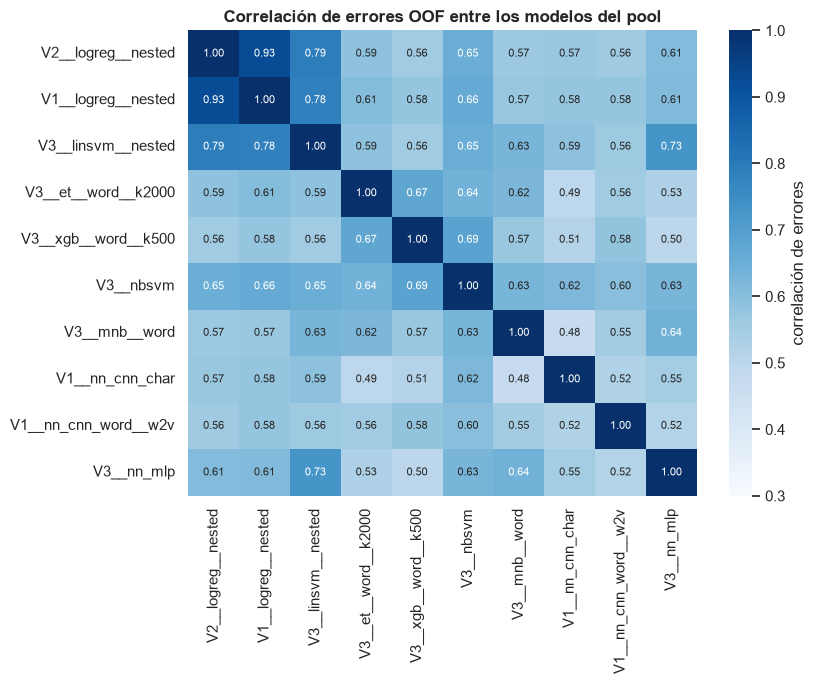

Correlación entre pares: mínima 0.478 (V3__mnb__word / V1__nn_cnn_char__tune-d0.3-lr0.002), máxima 0.926 (V2__logreg__nested / V1__logreg__nested), mediana 0.587
  correlación media con el núcleo lineal — núcleo lineal: 0.835
  correlación media con el núcleo lineal — diversidad clásica: 0.600
  correlación media con el núcleo lineal — redes: 0.599


In [13]:
P_MAIN = {m: stored(oof_store, m, train["id"]) for m in POOL}
P_TEST = {m: stored(test_store, m, test["id"]) for m in POOL}
P_FS = {"folds": P_MAIN}
RES = {}


def run(fs, key, method="single"):
    """Crossfit (ensemble.crossfit) de un modelo único (key = model_id), un subconjunto ('A'..'D') o una
    tupla de ids, con un método. Memoizado en RES."""
    ids = list(SUBSETS[key]) if key in SUBSETS else ([key] if isinstance(key, str) else list(key))
    k = (fs, key if isinstance(key, str) else tuple(key), method)
    if k not in RES:
        start = time.perf_counter()
        comb = en.Single(0) if method == "single" else en.make_combiner(method, CALIB)
        P = np.stack([P_FS[fs][m] for m in ids], axis=1)
        RES[k] = en.crossfit(comb, P, Y, FOLDSETS[fs], EMPTY_TR) | {"ids": ids, "seconds": time.perf_counter() - start}
    return RES[k]


def f1s(res, metric=METRIC, rule="plateau", hierarchy=True):
    return en.f1_folds(res, metric, rule, hierarchy)


CALIB = None  # los modelos únicos no usan calibración; se fija en la sección 2
errors = pd.DataFrame({m: (run("folds", m)["pred"] != Y).ravel().astype(int) for m in POOL})
corr = errors.corr()
short = {m: m.replace("__tune-d0.3-lr0.002", "").replace("__tune-d0.5-lr0.002", "") for m in POOL}
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr.rename(index=short, columns=short), annot=True, fmt=".2f", cmap="Blues", vmin=0.3, vmax=1,
            cbar_kws={"label": "correlación de errores"}, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlación de errores OOF entre los modelos del pool")
fig.tight_layout()
savefig(fig, "error_correlation")
plt.show()
off = corr.where(~np.eye(len(corr), dtype=bool)).stack()
print(f"Correlación entre pares: mínima {off.min():.3f} ({' / '.join(off.idxmin())}), máxima {off.max():.3f} "
      f"({' / '.join(off.idxmax())}), mediana {off.median():.3f}")
for grp, ids in {"núcleo lineal": CORE, "diversidad clásica": CLASSIC, "redes": NETS}.items():
    vals = [corr.loc[a, b] for a in ids for b in CORE if a != b]
    print(f"  correlación media con el núcleo lineal — {grp}: {np.mean(vals):.3f}")

**Interpretación:**
- **El pool está completo y es coherente con el registro.** Los 10 candidatos pasan todas las comprobaciones, y el F1 recalculado coincide con `registry.csv`. El boosting del pool es `V3__xgb__word__k500` (0.7494 frente a 0.7425 de LightGBM).
- **El núcleo lineal apenas aporta diversidad.** Sus tres modelos se equivocan casi en los mismos tuits: correlación de errores media de 0.835 entre ellos, y 0.926 entre las dos regresiones logísticas (V1 y V2), que solo difieren en el preprocesamiento.
- **La diversidad está fuera del núcleo.** Los modelos clásicos y las redes tienen una correlación media de ≈0.60 con el núcleo. El par menos correlacionado del pool es Multinomial NB con la CNN de caracteres (0.478).

## 2. Calibración (P10)

**Probabilidad calibrada:** un modelo está calibrado si, de todos los tuits a los que asigna una probabilidad de ≈0.7, aproximadamente el 70% son realmente positivos. Muchos modelos dan puntuaciones en [0, 1] que ordenan bien los tuits pero no son probabilidades:
- la regresión logística con `class_weight="balanced"` sube todas las probabilidades hacia la clase positiva;
- Naive Bayes las empuja hacia 0 y 1;
- los árboles las concentran en la zona central.

**Por qué importa al promediar:** si un modelo dice 0.9 donde otro dice 0.6 para el mismo nivel de confianza real, el promedio queda dominado por el de escala más extrema. Calibrar antes pone a todos en la misma escala.

**Métodos que se comparan** (cada calibrador se ajusta con las OOF de 4 folds y se aplica al 5.º):
- **sin calibrar:** las puntuaciones tal cual;
- **Platt:** una regresión logística sobre el logit de la puntuación. Solo aprende 2 números (pendiente y desplazamiento), así que es robusta con pocos datos;
- **isotónica:** una función escalonada creciente, sin forma fija. Es más flexible, pero puede sobreajustar con pocos datos;
- **cuantiles:** la función de distribución empírica de las OOF de entrenamiento (la posición relativa de la puntuación, entre 0 y 1). Iguala la escala de todos los modelos, pero **no es una probabilidad**: su salida es uniforme por construcción.

**Métricas:**
- **log-loss:** el promedio de −log(probabilidad asignada a la clase real). Castiga mucho la seguridad equivocada; menor es mejor;
- **Brier:** el error cuadrático medio entre la probabilidad y la etiqueta (0/1); menor es mejor;
- **diagrama de fiabilidad:** se agrupan los tuits por su probabilidad predicha (tramos de 0.1) y se dibuja la probabilidad media de cada tramo frente a la proporción real de positivos. Un modelo calibrado cae sobre la diagonal.

**Regla (fijada antes):** los métodos de ensamble que usan probabilidades calibradas (ii, iii y v) usan el método con **menor log-loss media** entre sin calibrar, Platt e isotónica (los cuantiles quedan fuera porque no son probabilidades). Un modelo se considera **descalibrado** si calibrarlo baja su log-loss en más de 0.01.

In [14]:
CAL_METHODS = ["none", "platt", "isotonic", "quantile"]
CAL_NAMES = {"none": "sin calibrar", "platt": "Platt", "isotonic": "isotónica", "quantile": "cuantiles"}


def calibrate_oof(p, y, f, method):
    out = np.zeros_like(p, dtype=float)
    for k in np.unique(f):
        val = f == k
        out[val] = en.Calibrator(method).fit(p[~val], y[~val]).transform(p[val])
    return out


CAL_OOF, rows = {}, []
for m in POOL:
    for meth in CAL_METHODS:
        Q = np.column_stack([calibrate_oof(P_MAIN[m][:, j], Y[:, j], folds, meth) for j in range(len(LABELS))])
        CAL_OOF[(m, meth)] = Q
        for j, lab in enumerate(LABELS):
            rows.append({"modelo": m, "método": CAL_NAMES[meth], "etiqueta": lab,
                         "log-loss": en.log_loss(Y[:, j], Q[:, j]), "Brier": en.brier(Y[:, j], Q[:, j])})
cal = pd.DataFrame(rows)
order = [CAL_NAMES[m] for m in CAL_METHODS]
cal_tab = cal.pivot_table(index="modelo", columns="método", values=["log-loss", "Brier"], aggfunc="mean")
cal_tab = cal_tab.reindex(columns=pd.MultiIndex.from_product([["log-loss", "Brier"], order])).loc[POOL]
display(cal_tab.round(4))
by_label = cal.pivot_table(index="etiqueta", columns="método", values="log-loss", aggfunc="mean")[order].loc[LABELS]
print("Log-loss media por etiqueta (media de los 10 modelos):")
display(by_label.round(4))
mean_ll = cal.groupby("método")["log-loss"].mean()[order]
print("Log-loss media de todos los modelos y etiquetas:", mean_ll.round(4).to_dict())
CALIB = min(["none", "platt", "isotonic"], key=lambda m: mean_ll[CAL_NAMES[m]])
gain = (cal_tab[("log-loss", "sin calibrar")] - cal_tab["log-loss"][["Platt", "isotónica"]].min(axis=1)).round(4)
print(f"Método elegido para (ii), (iii) y (v): {CAL_NAMES[CALIB]}")
print("Descalibrados (calibrar baja la log-loss > 0.01):",
      ", ".join(f"{m} ({g:+.3f})" for m, g in gain.sort_values(ascending=False).items() if g > 0.01) or "ninguno")
print("Bien calibrados:", ", ".join(m for m, g in gain.items() if g <= 0.01) or "ninguno")

log-loss                                    Brier                            
                                   sin calibrar   Platt isotónica cuantiles sin calibrar   Platt isotónica cuantiles
modelo                                                                                                              
V2__logreg__nested                       0.3933  0.3843    0.3869    0.4642       0.1187  0.1188    0.1190    0.1504
V1__logreg__nested                       0.3918  0.3819    0.3828    0.4625       0.1182  0.1181    0.1175    0.1498
V3__linsvm__nested                       0.3883  0.3896    0.3951    0.4692       0.1208  0.1212    0.1214    0.1527
V3__et__word__k2000                      0.4713  0.4458    0.4265    0.5122       0.1411  0.1361    0.1340    0.1679
V3__xgb__word__k500                      0.4395  0.4352    0.4507    0.5184       0.1375  0.1374    0.1376    0.1701
V3__nbsvm                                0.4418  0.4180    0.4113    0.4818       0.1391  0.1307    0.1269    0.1578
V3__mnb__word                            0.4862  0.4290    0.4414    0.5042       0.1599  0.1362    0.1378    0.1676
V1__nn_cnn_char__tune-d0.3-lr0.002       0.4085  0.4118    0.4174    0.4853       0.1285  0.1291    0.1287    0.1599
V1__nn_cnn_word__w2v                     0.3978  0.3997    0.4100    0.4802       0.1256  0.1261    0.1274    0.1580
V3__nn_mlp__tune-d0.5-lr0.002            0.4232  0.4240    0.4337    0.4975       0.1338  0.1340    0.1350    0.1646

Log-loss media por etiqueta (media de los 10 modelos):


método,sin calibrar,Platt,isotónica,cuantiles
etiqueta,,,,
HS,0.4755,0.4670,0.4718,0.4825
TR,0.3220,0.3074,0.3091,0.4702
AG,0.4751,0.4613,0.4659,0.5100


Log-loss media de todos los modelos y etiquetas: {'sin calibrar': 0.4242, 'Platt': 0.4119, 'isotónica': 0.4156, 'cuantiles': 0.4876}
Método elegido para (ii), (iii) y (v): Platt
Descalibrados (calibrar baja la log-loss > 0.01): V3__mnb__word (+0.057), V3__et__word__k2000 (+0.045), V3__nbsvm (+0.030)
Bien calibrados: V2__logreg__nested, V1__logreg__nested, V3__linsvm__nested, V3__xgb__word__k500, V1__nn_cnn_char__tune-d0.3-lr0.002, V1__nn_cnn_word__w2v, V3__nn_mlp__tune-d0.5-lr0.002


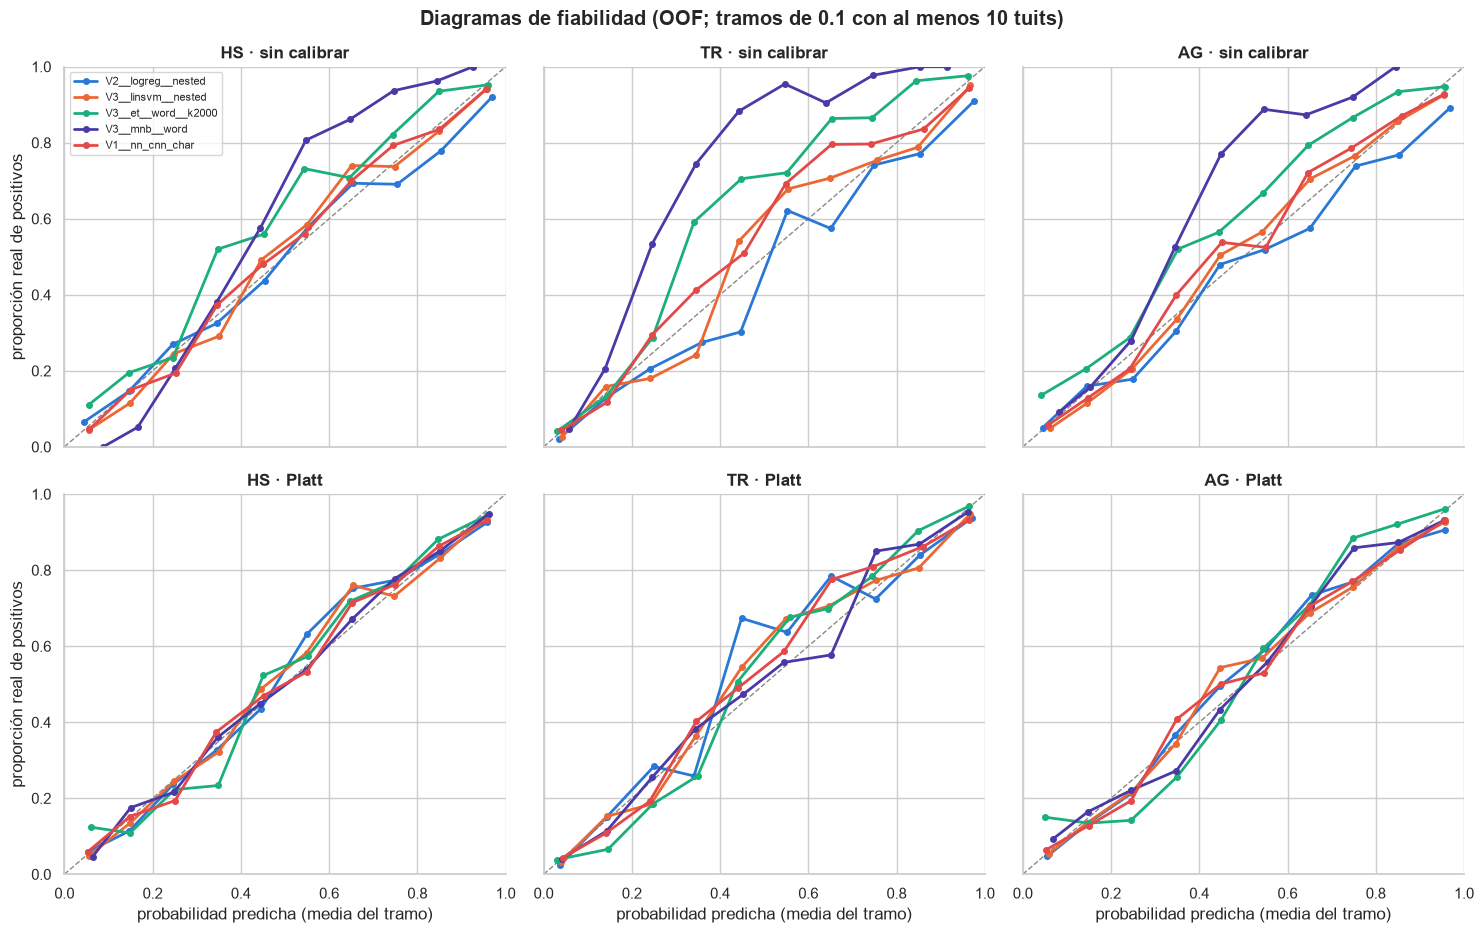

In [15]:
def reliability(y, p, bins=10, min_n=10):
    """(prob. media, frecuencia real, n) por tramo de probabilidad, solo tramos con >= min_n tuits."""
    idx = np.clip((np.asarray(p) * bins).astype(int), 0, bins - 1)
    return np.array([(p[idx == b].mean(), y[idx == b].mean(), (idx == b).sum()) for b in range(bins)
                     if (idx == b).sum() >= min_n])


REP = ["V2__logreg__nested", "V3__linsvm__nested", "V3__et__word__k2000", "V3__mnb__word",
       "V1__nn_cnn_char__tune-d0.3-lr0.002"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5), sharex=True, sharey=True)
for r, meth in enumerate(["none", CALIB]):
    for j, lab in enumerate(LABELS):
        ax = axes[r, j]
        ax.plot([0, 1], [0, 1], ls="--", color="#8a8984", lw=1)
        for c, m in zip(COLORS, REP):
            rel = reliability(Y[:, j], CAL_OOF[(m, meth)][:, j])
            ax.plot(rel[:, 0], rel[:, 1], marker="o", ms=4, lw=2, color=c, label=short[m])
        ax.set(title=f"{lab} · {CAL_NAMES[meth]}", xlabel="probabilidad predicha (media del tramo)" if r else "",
               ylabel="proporción real de positivos" if j == 0 else "", xlim=(0, 1), ylim=(0, 1))
axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle("Diagramas de fiabilidad (OOF; tramos de 0.1 con al menos 10 tuits)", fontweight="bold")
fig.tight_layout()
savefig(fig, "reliability_pool")
plt.show()

**Interpretación:**
- **Platt es el mejor método y se usa en (ii), (iii) y (v).** Log-loss media de 0.4119, frente a 0.4242 sin calibrar, 0.4156 con isotónica y 0.4876 con cuantiles.
- **La isotónica no supera a Platt.** Con ≈1400 tuits por fold, su flexibilidad sobreajusta.
- **Los cuantiles son los peores en log-loss y Brier, como se esperaba:** su salida es uniforme, no una probabilidad.
- **Modelos descalibrados** (calibrar baja la log-loss en más de 0.01):
  - Multinomial NB (−0.057): en los diagramas queda por encima de la diagonal y subestima la probabilidad en la zona media; por ejemplo, en TR, tuits con p ≈ 0.35 son positivos en un ≈75%;
  - ExtraTrees (−0.045): sus probabilidades se concentran en el centro;
  - NB-SVM (−0.030).
- **Modelos bien calibrados:**
  - las regresiones logísticas: calibrarlas mejora menos de 0.01, aunque `class_weight="balanced"` las hace sobrestimar algo los positivos en la parte alta (HS: a p ≈ 0.75, un ≈69% real);
  - la SVM lineal, que ya trae su propia sigmoide: Platt no la mejora (0.3896 frente a 0.3883);
  - XGBoost;
  - las tres redes, entrenadas con BCE sin `pos_weight`.
- **Después de Platt,** los cinco modelos del diagrama quedan cerca de la diagonal en las tres etiquetas.
- **Para el F1, calibrar importa poco:** con umbral ajustado, (ii) apenas cambia respecto a (i) (A: 0.7855 frente a 0.7858; D: 0.7924 frente a 0.7922). Donde sí importa es en los métodos que mezclan escalas: pesos, Caruana y stacking.

## 3. Métodos de ensamble

Seis métodos, de menos a más complejo. Todos reciben las probabilidades OOF de los modelos del subconjunto y devuelven una probabilidad por etiqueta:

1. **(i) Promedio simple** de las probabilidades, sin calibrar. Sin parámetros.
2. **(ii) Promedio calibrado:** se calibra cada modelo y etiqueta (método de la sección 2) y se promedia.
3. **(iii) Pesos por log-loss:** media ponderada de las probabilidades calibradas, con pesos ≥ 0 que suman 1, elegidos por etiqueta para minimizar la log-loss en los folds de entrenamiento.
4. **(iv) Stacking:**
   - "apilar" un segundo modelo encima de los primeros: un **meta-modelo** (aquí, una regresión logística L2 por etiqueta) aprende a combinar las salidas de los modelos base;
   - su entrada son los **logits** (log(p / (1 − p))) de **las 3 etiquetas de cada modelo**, así que puede aprovechar, por ejemplo, que una probabilidad alta de HS hace más probable TR o AG (la jerarquía HS → TR, AG);
   - la fuerza de la regularización, C ∈ {0.01, 0.1, 1}, se elige con una CV interna dentro de los folds de entrenamiento;
   - funciona porque las OOF son predicciones sobre tuits que cada modelo base no vio, como lo serán las del test.
5. **(v) Selección voraz con reemplazo (Caruana):**
   - se parte de un ensamble vacío y, en cada paso, se añade el modelo (aunque ya esté) que más baja la log-loss del promedio;
   - repetir un modelo equivale a darle más peso;
   - se hace en 20 "bolsas", cada una con una mitad de los modelos sorteada al azar (*bagging*), para que la selección no dependa de unos pocos tuits;
   - los pesos finales son la media entre bolsas. Todo se elige dentro de los folds de entrenamiento.
6. **(vi) Stacking con la etiqueta propia:** como (iv), pero cada meta-modelo solo ve los logits de su etiqueta. La diferencia (iv) − (vi) mide si la información entre etiquetas ayuda.

**Protocolo:** para cada fold externo k, el método se ajusta con las OOF de los otros 4 folds y se aplica al fold k. Los umbrales de la sección 4 se eligen también sin mirar el fold k.

In [16]:
print(f"Calibración usada por (ii), (iii) y (v): {CAL_NAMES[CALIB]} | C del stacking: {en.STACK_CS} | "
      f"Caruana: 20 bolsas, mitad de los modelos por bolsa, hasta 25 pasos")
for m in en.METHODS:
    print(f"  {en.METHOD_NAMES[m]:38s} -> {type(en.make_combiner(m, CALIB)).__name__}")

Calibración usada por (ii), (iii) y (v): Platt | C del stacking: (0.01, 0.1, 1.0) | Caruana: 20 bolsas, mitad de los modelos por bolsa, hasta 25 pasos
  (i) promedio simple                    -> Mean
  (ii) promedio calibrado                -> CalMean
  (iii) pesos por log-loss               -> Weighted
  (iv) stacking (todas las etiquetas)    -> Stacking
  (v) selección voraz (Caruana)          -> Caruana
  (vi) stacking (etiqueta propia)        -> Stacking


## 4. Umbrales y posprocesamiento

El F1 depende del **umbral** a partir del cual una probabilidad se convierte en 1. Elegirlo como el máximo exacto de la curva de F1 (*argmax*) sobreajusta: con ≈1400 tuits la curva tiene dientes, y el máximo cae a menudo en un pico estrecho que no se repite en datos nuevos.

**Meseta del umbral:**
1. se calcula el F1 de cada umbral de 0.05 a 0.95 (pasos de 0.01) sobre las predicciones de los 4 folds de entrenamiento;
2. se suaviza con un promedio móvil de ±0.03;
3. la **meseta** es el tramo continuo alrededor del máximo donde el F1 suavizado está a menos de 0.005 del máximo;
4. se toma su **centro**.

**Para que el umbral no mire el fold k,** las predicciones de los 4 folds de entrenamiento salen de una CV interna: el método se ajusta en 3 y predice el 4.º. Para un modelo único o el promedio simple, que no tienen parámetros, son directamente sus OOF.

**Posprocesamiento:**
- **jerarquía:** HS < umbral ⇒ TR = 0 (D7). Se reporta con y sin ella;
- **tuits vacíos** (`#¿NOMBRE?`) ⇒ 000 (D2). En el train no hay ninguno; en el test hay 6.

Mejor modelo único con este protocolo (E): V2__logreg__nested | F1 macro 0.7902


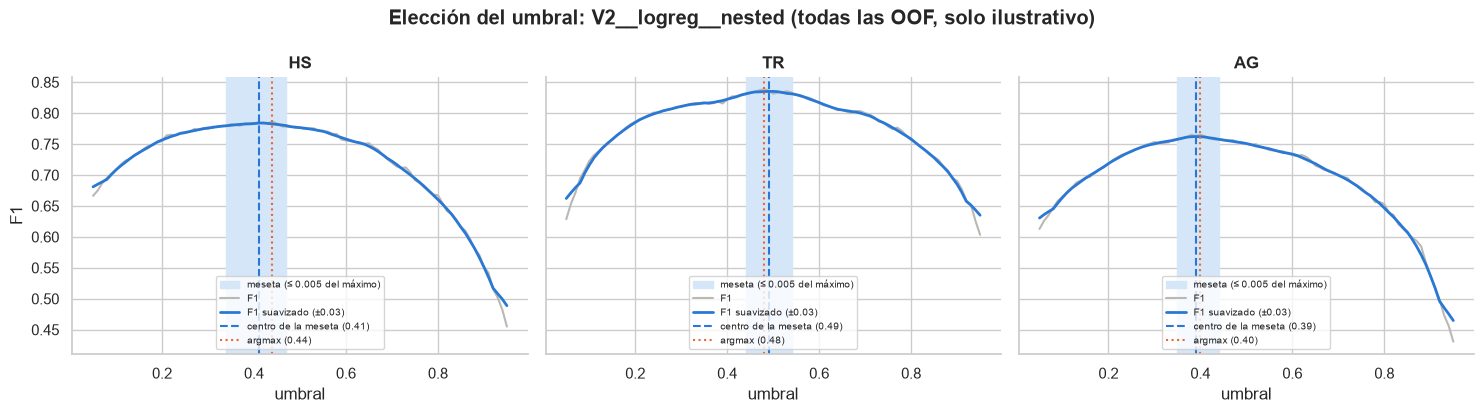

F1 HS   F1 TR   F1 AG  F1 macro   desv.  F1 micro
modelo             umbral  jerarquía                                                    
V2__logreg__nested argmax  sí         0.7859  0.8329  0.7622    0.7937  0.0216    0.7897
                           no         0.7859  0.8351  0.7622    0.7944  0.0190    0.7906
                   plateau sí         0.7805  0.8324  0.7576    0.7902  0.0192    0.7859
                           no         0.7805  0.8339  0.7576    0.7907  0.0185    0.7865
A-(i)              argmax  sí         0.7720  0.8238  0.7599    0.7852  0.0190    0.7809
                           no         0.7720  0.8340  0.7599    0.7886  0.0158    0.7840
                   plateau sí         0.7738  0.8242  0.7595    0.7858  0.0174    0.7815
                           no         0.7738  0.8348  0.7595    0.7894  0.0149    0.7846
B-(i)              argmax  sí         0.7840  0.8391  0.7497    0.7909  0.0229    0.7867
                           no         0.7840  0.8344  0.7497    0.7894  0.0237    0.7856
                   plateau sí         0.7837  0.8361  0.7538    0.7912  0.0255    0.7870
                           no         0.7837  0.8301  0.7538    0.7892  0.0254    0.7857
C-(i)              argmax  sí         0.7874  0.8410  0.7624    0.7969  0.0193    0.7923
                           no         0.7874  0.8357  0.7624    0.7951  0.0171    0.7911
                   plateau sí         0.7929  0.8392  0.7598    0.7973  0.0217    0.7933
                           no         0.7929  0.8349  0.7598    0.7959  0.0200    0.7924
D-(i)              argmax  sí         0.7868  0.8399  0.7654    0.7974  0.0237    0.7939
                           no         0.7868  0.8349  0.7654    0.7957  0.0233    0.7928
                   plateau sí         0.7853  0.8341  0.7570    0.7922  0.0229    0.7886
                           no         0.7853  0.8263  0.7570    0.7895  0.0218    0.7867

In [17]:
E = max(POOL, key=lambda m: f1s(run("folds", m)).mean())
print(f"Mejor modelo único con este protocolo (E): {E} | F1 macro {f1s(run('folds', E)).mean():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
pe = P_MAIN[E]
for j, (lab, ax) in enumerate(zip(LABELS, axes)):
    curve = en.f1_curve(Y[:, j], pe[:, j])
    sm = en.smooth(curve)
    thr_p, thr_a = en.plateau_threshold(Y[:, j], pe[:, j]), en.argmax_threshold(Y[:, j], pe[:, j])
    lo, hi = en.plateau_range(Y[:, j], pe[:, j])
    ax.axvspan(en.THRESHOLD_GRID[lo], en.THRESHOLD_GRID[hi], color="#d5e6f8", label="meseta (≤ 0.005 del máximo)")
    ax.plot(en.THRESHOLD_GRID, curve, color="#b9b8b2", lw=1.5, label="F1")
    ax.plot(en.THRESHOLD_GRID, sm, color=COLORS[0], lw=2, label="F1 suavizado (±0.03)")
    ax.axvline(thr_p, color=COLORS[0], ls="--", lw=1.5, label=f"centro de la meseta ({thr_p:.2f})")
    ax.axvline(thr_a, color=COLORS[1], ls=":", lw=1.5, label=f"argmax ({thr_a:.2f})")
    ax.set(title=lab, xlabel="umbral", ylabel="F1" if j == 0 else "")
    ax.legend(fontsize=7, loc="lower center")
fig.suptitle(f"Elección del umbral: {E} (todas las OOF, solo ilustrativo)", fontweight="bold")
fig.tight_layout()
savefig(fig, "threshold_plateau")
plt.show()

rows = []
for key, meth in [(E, "single")] + [(s, "mean") for s in SUBSETS]:
    r = run("folds", key, meth)
    for rule in ("argmax", "plateau"):
        for h in (True, False):
            t = r["folds"][(rule, h)]
            rows.append({"modelo": E if meth == "single" else f"{key}-(i)", "umbral": rule,
                         "jerarquía": "sí" if h else "no", **{f"F1 {lab}": round(t[f'F1_{lab}'].mean(), 4) for lab in LABELS},
                         "F1 macro": round(t["F1_macro"].mean(), 4), "desv.": round(t["F1_macro"].std(), 4),
                         "F1 micro": round(t["F1_micro"].mean(), 4)})
protocol = pd.DataFrame(rows).set_index(["modelo", "umbral", "jerarquía"])
display(protocol)

**Interpretación:**
- **E (el mejor único con este protocolo) es `V2__logreg__nested`,** con 0.7902 ± 0.0192. Es el mismo modelo que lidera el registro.
- **La meseta no sube el F1 de forma sistemática:**
  - en E baja 0.0035 respecto al argmax (0.7902 frente a 0.7937);
  - en C-(i) queda igual (0.7973 frente a 0.7969);
  - en D-(i) baja 0.005 (0.7922 frente a 0.7974).
  - Las dos reglas eligen el umbral sin mirar el fold, así que ambas son honestas y sus diferencias son ruido del orden de ±0.005.
  - La meseta se decidió a priori por estabilidad y se mantiene. En la figura de E, los centros (0.41 / 0.49 / 0.39) caen a 0.01–0.03 del argmax (0.44 / 0.48 / 0.40), dentro de mesetas de ≈0.1 de ancho.
- **El efecto de la jerarquía es pequeño y de signo variable:**
  - en E: 0.7902 con ella y 0.7907 sin ella;
  - en A-(i) sin ella se gana 0.0036, porque TR sube de 0.8242 a 0.8348;
  - en el modelo final (sección 7) con ella se gana 0.001.
  - Se mantiene por D7: no hay motivo consistente para cambiarla.

## 5. Evaluación: método × subconjunto, en `folds.csv` y en `folds_seed2.csv`

### 5a. OOF de `folds_seed2`

Para repetir la evaluación con el segundo conjunto de folds hacen falta las OOF de cada candidato con esos folds. Se reutilizan las que ya existen (la regresión logística anidada de V2 quedó en la caché del `06`), y se generan **solo las que faltan**, con exactamente la misma configuración de cada modelo:
- los modelos con CV anidada repiten la selección de hiperparámetros dentro de cada fold, con la rejilla del `04`;
- el resto usa sus hiperparámetros guardados;
- las redes, su configuración guardada con early stopping interno.

Para la tabla maestra (sección 11) se generan también las del mejor modelo de cada familia que no está en el pool. Antes de nada se comprueba que este código reproduce exactamente las OOF guardadas de `folds.csv` en los modelos baratos.

In [18]:
GRIDS_04 = {  # rejillas de la CV anidada del 04 (copiadas sin cambios)
    "logreg": [{"C": c} for c in (0.3, 1.0, 3.0, 10.0, 30.0)] + [{"C": c, "l1_ratio": 0.5} for c in (1.0, 3.0, 10.0)]
              + [{"C": c, "l1_ratio": 1.0} for c in (3.0, 10.0)],
    "linsvm": [{"C": c} for c in (0.03, 0.1, 0.3, 1.0, 3.0)],
    "rbfsvm": [{"C": c} for c in (0.3, 1.0, 3.0, 10.0)],
}


def family_group(mid):
    r = REG.loc[mid]
    if r["family"] == "neuronal":
        return {"nn_mlp": "MLP", "nn_cnn_word": "CNN", "nn_cnn_char": "CNN", "nn_bigru": "BiGRU/fastText",
                "nn_fasttext": "BiGRU/fastText"}[r["classifier"]]
    return {"lineal": "lineal", "bayes": "bayes", "kernel": "kernel", "árboles": "árboles", "boosting": "boosting",
            "transformer": "Transformer"}.get(r["family"])


GROUPS = ["lineal", "bayes", "kernel", "árboles", "boosting", "MLP", "CNN", "BiGRU/fastText", "Transformer"]
reg_sorted = REG[REG["notebook"].astype(str).str.zfill(2) != "07"].sort_values("F1_macro", ascending=False)
FAMILY_BEST = {g: next(m for m in reg_sorted.index if family_group(m) == g) for g in GROUPS}
EXTRA = [m for m in FAMILY_BEST.values() if m not in POOL]
print("Mejor de cada familia en el registro:", FAMILY_BEST)
print("Fuera del pool (solo para la tabla maestra):", EXTRA)


def build_cv_model(mid):
    """Reconstruye la configuración de CV de un modelo del registro."""
    r = REG.loc[mid]
    if r["family"] == "transformer":
        cfg = json.loads((md.MODELS_DIR / "06_transformer" / "cache" / mid / "config.json").read_text())
        return "net", nn_.TransformerTweetClassifier(**cfg, n_threads=FOLD_THREADS)
    if str(r["classifier"]).startswith("nn_"):
        params = md.load_model(mid).get_params()
        params.update(fixed_epochs=None, thresholds=0.5, n_threads=FOLD_THREADS)
        return "net", nn_.NeuralTweetClassifier(**params)
    if mid.endswith("__nested"):
        return "nested", (r["variant"], r["classifier"], r["features"])
    params = json.loads(r["params"]) or None
    return "sk", md.TweetToxicClassifier(variant=r["variant"], classifier=r["classifier"], features=r["features"],
                                         clf_params=params)


def oof_for(mid, fs):
    """OOF de mid con el conjunto de folds fs: de la caché (07 u otra carpeta de models/) o calculadas."""
    path = CACHE_DIR / f"{mid}__{fs}.npy"
    if path.exists():
        return np.load(path), "caché 07", 0.0
    if fs == "folds_seed2":
        other = sorted(md.MODELS_DIR.glob(f"*/cache/{mid}__folds2.pt"))
        if other:
            oof = torch.load(other[0], weights_only=True).numpy()
            np.save(path, oof)
            return oof, f"caché {other[0].parent.parent.name}", 0.0
    kind, model = build_cv_model(mid)
    # Procesos de joblib nuevos para cada modelo: si un proceso ya cargó la librería OpenMP de torch (p. ej.,
    # vía spaCy) y después entrena LightGBM o xgboost, el proceso muere con un segmentation fault.
    nn_._fresh_workers()
    start = time.perf_counter()
    f = pd.Series(FOLDSETS[fs])
    if kind == "net":
        cv = nn_.cached_cross_validate(model, texts, Y, f, CACHE_DIR / f"{mid}__{fs}", n_jobs=N_JOBS)
    elif kind == "nested":
        variant, clf, feats = model
        cv = md.nested_cross_validate(variant, clf, feats, GRIDS_04[clf], texts, Y, f, n_jobs=N_JOBS)
    else:
        cv = md.cross_validate(model, texts, Y, f, n_jobs=N_JOBS)
    np.save(path, cv["oof"])
    return cv["oof"], "calculada", time.perf_counter() - start

Mejor de cada familia en el registro: {'lineal': 'V2__logreg__nested', 'bayes': 'V4__cnb__word', 'kernel': 'V3__rbfsvm__nested', 'árboles': 'V3__et__word__k2000', 'boosting': 'V1__lgbm__word+hand__k2000', 'MLP': 'V3__nn_mlp__tune-d0.5-lr0.002', 'CNN': 'V1__nn_cnn_char__tune-d0.3-lr0.002', 'BiGRU/fastText': 'V3__nn_bigru__w2v', 'Transformer': 'V1__nn_trf_bpe__v800-d128-l2-aug'}
Fuera del pool (solo para la tabla maestra): ['V4__cnb__word', 'V3__rbfsvm__nested', 'V1__lgbm__word+hand__k2000', 'V3__nn_bigru__w2v', 'V1__nn_trf_bpe__v800-d128-l2-aug']


In [19]:
CHECK = ["V3__nbsvm", "V3__mnb__word", "V3__et__word__k2000", BOOSTING, "V3__nn_mlp__tune-d0.5-lr0.002"]
rows = []
for m in CHECK:
    oof, src, sec = oof_for(m, "folds")
    rows.append({"modelo": m, "origen": src, "máx. |diferencia| con la OOF guardada": float(np.abs(oof - P_MAIN[m]).max())})
recon = pd.DataFrame(rows).set_index("modelo")
display(recon)
print("Reconstrucción exacta (≤ 1e-9):", bool((recon.iloc[:, -1] <= 1e-9).all()))

,origen,máx. |diferencia| con la OOF guardada
modelo,,
V3__nbsvm,caché 07,0.0
V3__mnb__word,caché 07,0.0
V3__et__word__k2000,caché 07,0.0
V3__xgb__word__k500,caché 07,0.0
V3__nn_mlp__tune-d0.5-lr0.002,caché 07,0.0


Reconstrucción exacta (≤ 1e-9): True


In [20]:
todo = POOL + EXTRA
missing = [m for m in todo if not (CACHE_DIR / f"{m}__folds_seed2.npy").exists()
           and not list(md.MODELS_DIR.glob(f"*/cache/{m}__folds2.pt"))]
est = REG.loc[missing, "cv_seconds"].fillna(0).sum() if missing else 0
print(f"OOF de folds_seed2 por calcular: {len(missing)} de {len(todo)} | estimación ≈{est / 60:.0f} min "
      f"(tiempo de CV del registro)")
P_SEED2, T_START = {}, time.perf_counter()
for i, m in enumerate(todo, 1):
    print(f"[{i}/{len(todo)}] {m} ...", end=" ", flush=True)
    oof, src, sec = oof_for(m, "folds_seed2")
    P_SEED2[m] = oof
    f1 = md._summarize_folds(oof, Y, pd.Series(folds2))[1]["F1_macro"]
    print(f"F1 macro {f1.mean():.4f} ± {f1.std():.4f} (protocolo del registro) | {src} | {sec:.0f} s | "
          f"total {(time.perf_counter() - T_START) / 60:.1f} min", flush=True)
P_FS["folds_seed2"] = P_SEED2
for m in EXTRA:
    P_MAIN[m] = stored(oof_store, m, train["id"])

OOF de folds_seed2 por calcular: 3 de 15 | estimación ≈6 min (tiempo de CV del registro)
[1/15] V2__logreg__nested ... F1 macro 0.7856 ± 0.0178 (protocolo del registro) | caché 07 | 0 s | total 0.0 min
[2/15] V1__logreg__nested ... F1 macro 0.7894 ± 0.0151 (protocolo del registro) | caché 07 | 0 s | total 0.0 min
[3/15] V3__linsvm__nested ... F1 macro 0.7796 ± 0.0237 (protocolo del registro) | caché 07 | 0 s | total 0.0 min
[4/15] V3__et__word__k2000 ... F1 macro 0.7515 ± 0.0093 (protocolo del registro) | caché 07 | 0 s | total 0.1 min
[5/15] V3__xgb__word__k500 ... F1 macro 0.7446 ± 0.0207 (protocolo del registro) | caché 07 | 0 s | total 0.1 min
[6/15] V3__nbsvm ... F1 macro 0.7676 ± 0.0241 (protocolo del registro) | caché 07 | 0 s | total 0.1 min
[7/15] V3__mnb__word ... F1 macro 0.7448 ± 0.0201 (protocolo del registro) | caché 07 | 0 s | total 0.1 min
[8/15] V1__nn_cnn_char__tune-d0.3-lr0.002 ... F1 macro 0.7627 ± 0.0172 (protocolo del registro) | caché 07 | 0 s | total 0.1 min
[9/

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


F1 macro 0.7323 ± 0.0239 (protocolo del registro) | calculada | 46 s | total 1.1 min
[15/15] V1__nn_trf_bpe__v800-d128-l2-aug ... F1 macro 0.6924 ± 0.0246 (protocolo del registro) | calculada | 240 s | total 5.1 min


**Interpretación de 5a:**
- **El código reproduce exactamente las OOF guardadas** (diferencia 0.0) en los cinco modelos baratos. Las OOF de `folds_seed2` salen de las mismas configuraciones del 04 y el 05.
- **Origen de las OOF de `folds_seed2`:** la de la regresión logística anidada de V2 se reutilizó (da 0.7856, la cifra de H43) y las otras 14 se calcularon.
- **En `folds_seed2`, el orden de los modelos únicos se mantiene en lo grueso:**
  - V1 logística 0.7894, SVM RBF 0.7885, CNN de palabras 0.7775 (+0.013 frente a los folds principales), CNN de caracteres 0.7627;
  - ExtraTrees baja a 0.7515 (−0.016).

### 5b. Resultados

Para cada subconjunto (A–D) y cada método (i–vi): F1 macro (media ± desviación entre folds) y la **diferencia pareada por fold frente a E** (el mejor único, con el mismo protocolo de umbrales y jerarquía), con el número de folds a favor.

**Optimismo residual:** los métodos se ajustan sobre OOF, que son predicciones honestas de los modelos base. Pero esas OOF salen de modelos cuyos hiperparámetros se eligieron mirando los mismos folds (en el 04 y el 05). Además, la OOF de un tuit de entrenamiento procede de un modelo base que sí vio el fold de validación. El optimismo es pequeño, porque los combinadores tienen pocos parámetros (≤ 30 por etiqueta), pero existe. `folds_seed2` es la comprobación: otra partición de los mismos datos, con las OOF regeneradas.

In [21]:
grid_rows = []
for fs in FOLDSETS:
    ref = f1s(run(fs, E))
    for s in SUBSETS:
        for meth in en.METHODS:
            r = run(fs, s, meth)
            f = f1s(r)
            d = en.paired_delta(f, ref)
            grid_rows.append({"folds": fs, "subconjunto": s, "método": meth, "F1": f.mean(), "desv.": f.std(),
                              "micro": f1s(r, "micro").mean(), "Δ": d["Δ"], "Δ desv.": d["Δ desv."],
                              "a favor": d["folds a favor"], "segundos": r["seconds"]})
GRID = pd.DataFrame(grid_rows)
wide = GRID.pivot_table(index=["subconjunto", "método"], columns="folds",
                        values=["F1", "desv.", "micro", "Δ", "Δ desv.", "a favor"], aggfunc="first")
show = pd.DataFrame(index=wide.index)
for fs in FOLDSETS:
    show[f"F1 macro ({fs})"] = [f"{a:.4f} ± {b:.4f}" for a, b in zip(wide[("F1", fs)], wide[("desv.", fs)])]
    show[f"Δ vs E ({fs})"] = [f"{a:+.4f} ± {b:.4f} ({int(c)}/5)" for a, b, c in
                              zip(wide[("Δ", fs)], wide[("Δ desv.", fs)], wide[("a favor", fs)])]
    show[f"micro ({fs})"] = wide[("micro", fs)].round(4)
show = show.reindex([(s, m) for s in SUBSETS for m in en.METHODS])
show.index = [f"{s} · {en.METHOD_NAMES[m]}" for s, m in show.index]
for fs in FOLDSETS:
    f = f1s(run(fs, E))
    print(f"E = {E} en {fs}: F1 macro {f.mean():.4f} ± {f.std():.4f} | micro {f1s(run(fs, E), 'micro').mean():.4f}")
display(show)
print(f"Tiempo total de los 48 crossfits: {GRID['segundos'].sum():.0f} s")

E = V2__logreg__nested en folds: F1 macro 0.7902 ± 0.0192 | micro 0.7859
E = V2__logreg__nested en folds_seed2: F1 macro 0.7852 ± 0.0191 | micro 0.7811


,F1 macro (folds),Δ vs E (folds),micro (folds),F1 macro (folds_seed2),Δ vs E (folds_seed2),micro (folds_seed2)
A · (i) promedio simple,0.7858 ± 0.0174,-0.0043 ± 0.0070 (1/5),0.7815,0.7884 ± 0.0211,+0.0032 ± 0.0031 (4/5),0.7851
A · (ii) promedio calibrado,0.7855 ± 0.0194,-0.0047 ± 0.0096 (1/5),0.7811,0.7894 ± 0.0215,+0.0042 ± 0.0046 (4/5),0.7862
A · (iii) pesos por log-loss,0.7849 ± 0.0190,-0.0053 ± 0.0078 (1/5),0.7809,0.7916 ± 0.0209,+0.0064 ± 0.0066 (5/5),0.7883
A · (iv) stacking (todas las etiquetas),0.7887 ± 0.0207,-0.0015 ± 0.0077 (2/5),0.7849,0.7925 ± 0.0248,+0.0073 ± 0.0079 (4/5),0.7894
A · (v) selección voraz (Caruana),0.7884 ± 0.0188,-0.0018 ± 0.0083 (2/5),0.7844,0.7908 ± 0.0197,+0.0056 ± 0.0047 (5/5),0.7874
A · (vi) stacking (etiqueta propia),0.7866 ± 0.0180,-0.0036 ± 0.0075 (1/5),0.7822,0.7887 ± 0.0225,+0.0034 ± 0.0046 (4/5),0.7853
B · (i) promedio simple,0.7912 ± 0.0255,+0.0010 ± 0.0140 (2/5),0.7870,0.7900 ± 0.0225,+0.0047 ± 0.0067 (4/5),0.7869
B · (ii) promedio calibrado,0.7907 ± 0.0230,+0.0005 ± 0.0146 (2/5),0.7870,0.7834 ± 0.0197,-0.0019 ± 0.0053 (3/5),0.7803
B · (iii) pesos por log-loss,0.7895 ± 0.0201,-0.0007 ± 0.0069 (2/5),0.7851,0.7902 ± 0.0188,+0.0050 ± 0.0041 (5/5),0.7869
B · (iv) stacking (todas las etiquetas),0.7913 ± 0.0214,+0.0011 ± 0.0066 (2/5),0.7872,0.7871 ± 0.0274,+0.0019 ± 0.0087 (3/5),0.7842


Tiempo total de los 48 crossfits: 42 s


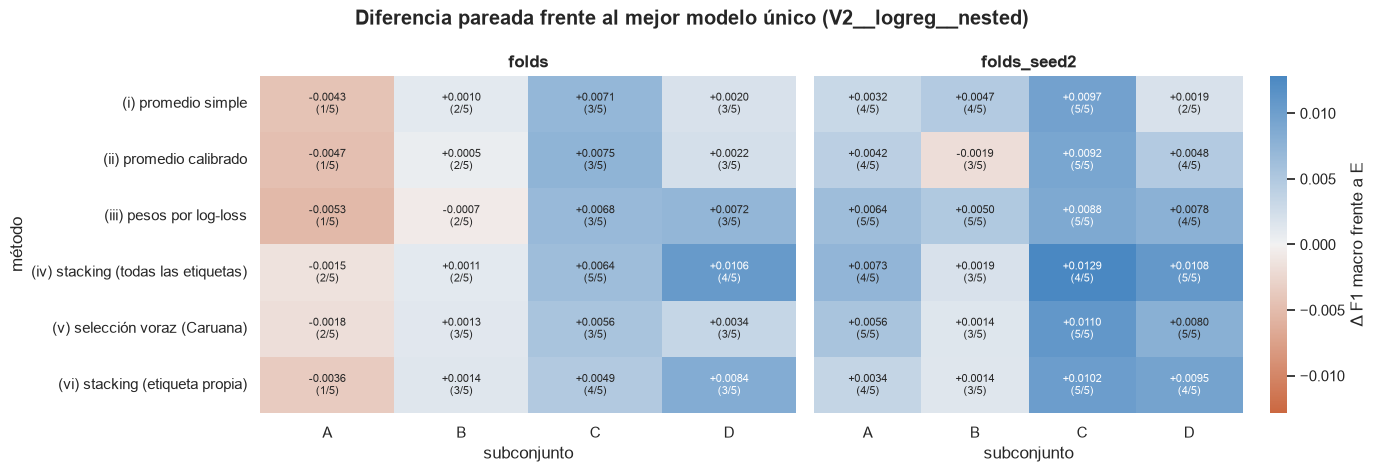

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
lim = np.abs(GRID["Δ"]).max()
cmap = sns.diverging_palette(25, 245, s=75, l=55, as_cmap=True)
for ax, fs in zip(axes, FOLDSETS):
    g = GRID[GRID["folds"] == fs].pivot(index="método", columns="subconjunto", values="Δ").loc[en.METHODS]
    fav = GRID[GRID["folds"] == fs].pivot(index="método", columns="subconjunto", values="a favor").loc[en.METHODS]
    labels = np.array([[f"{v:+.4f}\n({int(n)}/5)" for v, n in zip(rv, rn)] for rv, rn in zip(g.to_numpy(), fav.to_numpy())])
    sns.heatmap(g, annot=labels, fmt="", cmap=cmap, center=0, vmin=-lim, vmax=lim, ax=ax, annot_kws={"size": 8},
                cbar=ax is axes[-1], cbar_kws={"label": "Δ F1 macro frente a E"})
    ax.set(title=fs, xlabel="subconjunto", ylabel="" if ax is axes[1] else "método")
    ax.set_yticklabels([en.METHOD_NAMES[m] for m in en.METHODS], rotation=0)
fig.suptitle(f"Diferencia pareada frente al mejor modelo único ({E})", fontweight="bold")
fig.tight_layout()
savefig(fig, "ensemble_grid")
plt.show()

**Interpretación** (E: 0.7902 ± 0.0192 en `folds.csv` y 0.7852 ± 0.0191 en `folds_seed2`):
- **A (solo el núcleo lineal) no mejora a E en `folds.csv`** (Δ de −0.0015 a −0.0053, 1–2 de 5 folds a favor). En `folds_seed2` gana un poco (+0.003 a +0.007). Combinar tres modelos con correlación de errores de 0.78–0.93 no aporta información nueva.
- **B (+ diversidad clásica) queda en empate:** −0.0007 a +0.0014 en `folds.csv`. Árboles, boosting y NB son más débiles (0.737–0.771) y su diversidad no compensa.
- **C (+ redes) es el subconjunto más consistente:**
  - los seis métodos ganan en ambos conjuntos de folds: +0.005 a +0.0075 en `folds.csv` y +0.009 a +0.013 en `folds_seed2`;
  - las redes aportan la diversidad útil.
- **D (todo el pool) da el máximo con stacking:** +0.0106 ± 0.0108 (4/5) en `folds.csv` y +0.0108 ± 0.0065 (5/5) en `folds_seed2`.
  - El promedio simple de D se queda en +0.002: mezclar a partes iguales modelos débiles y descalibrados diluye a los buenos;
  - el stacking aprende a ponderarlos.
- **La información entre etiquetas ayuda poco pero de forma consistente.** El stacking con las 3 etiquetas supera al de la etiqueta propia en A, C y D en ambos conjuntos de folds:
  - D: 0.8008 frente a 0.7986 en `folds.csv`, y 0.7961 frente a 0.7948 en `folds_seed2`;
  - es una ganancia de +0.001 a +0.004, dentro del ruido de cada comparación.
- **Caruana y los pesos por log-loss quedan parecidos:** diferencias de ≤ 0.004 en uno u otro sentido.
- **La F1 micro sigue el mismo orden que la macro.**
- **Cuidado con la selección:** el candidato es el máximo de 24 combinaciones en `folds.csv`, lo que lo favorece. Que `folds_seed2` dé la misma ganancia (+0.0108, 5/5) indica que no es suerte de una partición concreta. Pero `folds_seed2` usa los mismos 1731 tuits, así que no son datos independientes.

## 6. Decisión según la regla

Se aplica la regla del principio, sin ajustes.

In [23]:
METHOD_RANK = {"single": 0, **{m: i + 1 for i, m in enumerate(en.METHODS)}}
FAMILY_RANK = {"lineal": 0, "bayes": 1, "árboles": 2, "boosting": 3, "neuronal": 4}
VARIANT_RANK = {"V0": 0, "V1": 1, "V2": 2, "V2 (alarg.=1)": 3, "V3": 4, "V4": 5}


def complexity(key, method):
    if method == "single":
        return (1, 0, FAMILY_RANK.get(REG.loc[key, "family"], 9), VARIANT_RANK.get(REG.loc[key, "variant"], 9))
    return (len(SUBSETS[key]), METHOD_RANK[method], 0, 0)


def label(c):
    key, meth = c
    return key if meth == "single" else f"{key} · {en.METHOD_NAMES[meth]}"


def delta(a, b, fs="folds"):
    return en.paired_delta(f1s(run(fs, *a)), f1s(run(fs, *b)))


def tied(a, b, fs="folds"):
    d = delta(a, b, fs)
    return a == b or abs(d["Δ"]) < d["Δ desv."]


combos = [(s, m) for s in SUBSETS for m in en.METHODS]
CAND = max(combos, key=lambda c: (round(f1s(run("folds", *c)).mean(), 10), tuple(-x for x in complexity(*c))))
d1, d2 = delta(CAND, (E, "single"), "folds"), delta(CAND, (E, "single"), "folds_seed2")
ok1 = d1["Δ"] >= 0.005 and d1["folds a favor"] >= 4
ok2 = d2["Δ"] >= 0.005 and d2["folds a favor"] >= 4
ADOPT = ok1 and ok2
print(f"Candidato a ensamble (mayor F1 en folds.csv): {label(CAND)} | F1 {f1s(run('folds', *CAND)).mean():.4f}")
print(f"  folds.csv:       Δ vs E {d1['Δ']:+.4f} ± {d1['Δ desv.']:.4f} ({d1['folds a favor']}/5) -> {'cumple' if ok1 else 'NO cumple'}")
print(f"  folds_seed2.csv: Δ vs E {d2['Δ']:+.4f} ± {d2['Δ desv.']:.4f} ({d2['folds a favor']}/5) -> {'cumple' if ok2 else 'NO cumple'}")
print(f"Se adopta el ensamble: {'SÍ' if ADOPT else 'NO'}")
passing = [c for c in combos if all(delta(c, (E, "single"), fs)["Δ"] >= 0.005 and delta(c, (E, "single"), fs)["folds a favor"] >= 4
                                    for fs in FOLDSETS)]
print(f"Combinaciones que cumplirían la regla en ambos conjuntos de folds (informativo, no elige): {len(passing)} de {len(combos)}"
      + (f" -> {', '.join(label(c) for c in passing)}" if passing else ""))

singles_tied = [m for m in POOL if tied((m, "single"), (E, "single"))]
SIMPLEST = min(singles_tied, key=lambda m: (complexity(m, "single"), -f1s(run("folds", m)).mean()))
print(f"Modelos únicos empatados con E en folds.csv: {singles_tied} -> el más simple: {SIMPLEST}")
if ADOPT:
    FINAL_A, FINAL_B = CAND, (SIMPLEST, "single")
else:
    FINAL_A = (SIMPLEST, "single")
    core_mean = ("A", "mean")
    d = delta(core_mean, FINAL_A)
    worse = d["Δ"] < 0 and abs(d["Δ"]) >= d["Δ desv."]
    if not worse:
        FINAL_B = core_mean
    else:
        rest = [m for m in sorted(singles_tied, key=lambda m: (complexity(m, "single"), -f1s(run("folds", m)).mean()))
                if m != SIMPLEST]
        FINAL_B = (E, "single") if E != SIMPLEST else (rest[0] if rest else E, "single")
for name, c in [("FINAL_A", FINAL_A), ("FINAL_B", FINAL_B)]:
    f, f2 = f1s(run("folds", *c)), f1s(run("folds_seed2", *c))
    print(f"{name}: {label(c)} | F1 macro {f.mean():.4f} ± {f.std():.4f} (folds) | {f2.mean():.4f} ± {f2.std():.4f} (folds_seed2) | "
          f"micro {f1s(run('folds', *c), 'micro').mean():.4f}")

Candidato a ensamble (mayor F1 en folds.csv): D · (iv) stacking (todas las etiquetas) | F1 0.8008
  folds.csv:       Δ vs E +0.0106 ± 0.0108 (4/5) -> cumple
  folds_seed2.csv: Δ vs E +0.0108 ± 0.0065 (5/5) -> cumple
Se adopta el ensamble: SÍ
Combinaciones que cumplirían la regla en ambos conjuntos de folds (informativo, no elige): 2 de 24 -> C · (iv) stacking (todas las etiquetas), D · (iv) stacking (todas las etiquetas)
Modelos únicos empatados con E en folds.csv: ['V2__logreg__nested', 'V1__logreg__nested', 'V3__linsvm__nested'] -> el más simple: V1__logreg__nested
FINAL_A: D · (iv) stacking (todas las etiquetas) | F1 macro 0.8008 ± 0.0180 (folds) | 0.7961 ± 0.0212 (folds_seed2) | micro 0.7968
FINAL_B: V1__logreg__nested | F1 macro 0.7871 ± 0.0166 (folds) | 0.7930 ± 0.0157 (folds_seed2) | micro 0.7832


**Decisión: se adopta el ensamble.**
- **El candidato** `D · (iv) stacking (todas las etiquetas)` cumple la regla en los dos conjuntos de folds:
  - `folds.csv`: +0.0106 ± 0.0108, 4/5;
  - `folds_seed2`: +0.0108 ± 0.0065, 5/5.
- **Solo otra combinación cumpliría la regla en ambos** (de 24): C con el mismo stacking.
- **FINAL_A = `ens07__D__stack-all`:**
  - F1 macro 0.8008 ± 0.0180 (`folds.csv`) y 0.7961 ± 0.0212 (`folds_seed2`);
  - F1 micro 0.7968.
- **FINAL_B = `V1__logreg__nested`:**
  - los tres lineales del núcleo empatan con E;
  - el más simple es la logística de V1, que lleva menos pasos de preprocesamiento que la de V2;
  - F1 macro 0.7871 ± 0.0166 y 0.7930 ± 0.0157; F1 micro 0.7832.
- **La ganancia es real pero modesta:** +0.011 es algo más de la mitad de la desviación entre folds de cada modelo (≈0.018–0.021).

## 7. Sensibilidad (diagnóstico; no cambia la decisión)

- **¿Qué aporta cada modelo y cada familia?** Se quita uno (o una familia) del candidato a ensamble y se repite el crossfit en `folds.csv`. Δ negativo = el ensamble empeora sin él, así que aporta.
- **Jerarquía y umbral:** el F1 de E, del candidato y de los dos finales con y sin jerarquía, y con umbral de meseta frente a argmax.
- **Artefacto de comillas (H3, P3):** cuánto cambiaría el F1 de AG si se forzara AG=1 en los tuits con `;` o `"`. **Solo diagnóstico, desactivado por defecto y pendiente de la consulta al profesor:** es un artefacto del archivo, no lenguaje.

In [24]:
key, meth = CAND
members = SUBSETS[key]
base_f = f1s(run("folds", key, meth))
rows = []
for m in members:
    r = run("folds", tuple(x for x in members if x != m), meth)
    d = en.paired_delta(f1s(r), base_f)
    rows.append({"se quita": m, "familia": REG.loc[m, "family"], "F1 macro": round(f1s(r).mean(), 4),
                 "Δ vs candidato": f"{d['Δ']:+.4f} ± {d['Δ desv.']:.4f} ({d['folds a favor']}/5)", "Δ": d["Δ"]})
fams = sorted({REG.loc[m, "family"] for m in members})
for fam in fams if len(fams) > 1 else []:
    keep = tuple(x for x in members if REG.loc[x, "family"] != fam)
    r = run("folds", keep, meth)
    d = en.paired_delta(f1s(r), base_f)
    rows.append({"se quita": f"familia {fam}", "familia": fam, "F1 macro": round(f1s(r).mean(), 4),
                 "Δ vs candidato": f"{d['Δ']:+.4f} ± {d['Δ desv.']:.4f} ({d['folds a favor']}/5)", "Δ": d["Δ"]})
loo = pd.DataFrame(rows).set_index("se quita")
print(f"Candidato: {label(CAND)} | F1 macro {base_f.mean():.4f}")
display(loo.drop(columns="Δ"))

rows = []
for name, c in [("E", (E, "single")), ("candidato", CAND), ("FINAL_A", FINAL_A), ("FINAL_B", FINAL_B)]:
    r = run("folds", *c)
    rows.append({"modelo": f"{name}: {label(c)}",
                 **{f"{rule} · jerarquía {'sí' if h else 'no'}": round(f1s(r, rule=rule, hierarchy=h).mean(), 4)
                    for rule in ("plateau", "argmax") for h in (True, False)}})
display(pd.DataFrame(rows).set_index("modelo"))

Candidato: D · (iv) stacking (todas las etiquetas) | F1 macro 0.8008


,familia,F1 macro,Δ vs candidato
se quita,,,
V2__logreg__nested,lineal,0.7977,-0.0031 ± 0.0033 (0/5)
V1__logreg__nested,lineal,0.7960,-0.0048 ± 0.0011 (0/5)
V3__linsvm__nested,lineal,0.7993,-0.0015 ± 0.0025 (2/5)
V3__et__word__k2000,árboles,0.7997,-0.0011 ± 0.0079 (2/5)
V3__xgb__word__k500,boosting,0.7990,-0.0018 ± 0.0031 (2/5)
V3__nbsvm,lineal,0.7996,-0.0012 ± 0.0052 (2/5)
V3__mnb__word,bayes,0.7983,-0.0025 ± 0.0019 (0/5)
V1__nn_cnn_char__tune-d0.3-lr0.002,neuronal,0.7951,-0.0057 ± 0.0049 (1/5)
V1__nn_cnn_word__w2v,neuronal,0.7975,-0.0033 ± 0.0066 (1/5)


,plateau · jerarquía sí,plateau · jerarquía no,argmax · jerarquía sí,argmax · jerarquía no
modelo,,,,
E: V2__logreg__nested,0.7902,0.7907,0.7937,0.7944
candidato: D · (iv) stacking (todas las etiquetas),0.8008,0.7998,0.7988,0.7981
FINAL_A: D · (iv) stacking (todas las etiquetas),0.8008,0.7998,0.7988,0.7981
FINAL_B: V1__logreg__nested,0.7871,0.7892,0.7877,0.7904


In [25]:
FORCE_AG_ARTIFACT = False  # PENDIENTE DE LA CONSULTA AL PROFESOR (P3). Solo diagnóstico: no se usa en ningún modelo final.
rows = []
for name, c in [("E", (E, "single")), ("candidato", CAND), ("FINAL_A", FINAL_A)]:
    r = run("folds", *c)
    forced = r["pred"].copy()
    forced[ARTIFACT_TR, LABELS.index("AG")] = 1
    for tag, pred in [("tal cual", r["pred"]), ("AG=1 forzado en H3", forced)]:
        per = pd.DataFrame([en.metrics(Y[folds == k], pred[folds == k]) for k in sorted(np.unique(folds))])
        rows.append({"modelo": f"{name}: {label(c)}", "regla": tag, "F1 AG": round(per["F1_AG"].mean(), 4),
                     "F1 macro": round(per["F1_macro"].mean(), 4)})
art = pd.DataFrame(rows).set_index(["modelo", "regla"])
display(art)
print(f"Tuits con el artefacto: train {ARTIFACT_TR.sum()} (todos con AG=1: {bool(Y[ARTIFACT_TR, 2].all())}), "
      f"test {ARTIFACT_TE.sum()} | FORCE_AG_ARTIFACT = {FORCE_AG_ARTIFACT} (no se aplica a los envíos)")

F1 AG  F1 macro
modelo                                             regla                               
E: V2__logreg__nested                              tal cual            0.7576    0.7902
                                                   AG=1 forzado en H3  0.7752    0.7960
candidato: D · (iv) stacking (todas las etiquetas) tal cual            0.7735    0.8008
                                                   AG=1 forzado en H3  0.7892    0.8060
FINAL_A: D · (iv) stacking (todas las etiquetas)   tal cual            0.7735    0.8008
                                                   AG=1 forzado en H3  0.7892    0.8060

Tuits con el artefacto: train 51 (todos con AG=1: True), test 34 | FORCE_AG_ARTIFACT = False (no se aplica a los envíos)


**Interpretación:**
- **Quitar un modelo nunca mejora el candidato.**
  - Δ de −0.0011 a −0.0057, ninguno por encima del ruido.
  - Los que más aportan:
    - la CNN de caracteres (−0.0057 ± 0.0049, 1/5);
    - la logística de V1 (−0.0048 ± 0.0011, 0/5; pequeño pero consistente);
    - Multinomial NB (−0.0025 ± 0.0019, 0/5).
- **Por familias:**
  - quitar el núcleo lineal cuesta −0.0133 (0/5) y quitar las redes −0.0095 (1/5);
  - árboles, boosting y bayes aportan cada uno ≤ 0.0025. Coincide con lo que se vio en B frente a C.
- **Jerarquía y umbral en FINAL_A:** con jerarquía, 0.8008 frente a 0.7998 sin ella; con meseta, 0.8008 frente a 0.7988 con argmax. En E las dos reglas van en sentido contrario. Ninguna de las dos decisiones mueve el resultado más allá del ruido.
- **Artefacto de comillas (diagnóstico; pendiente de P3):**
  - forzar AG=1 en los 51 tuits con `;` o `"` subiría el F1 de AG de 0.7735 a 0.7892 en FINAL_A, y el F1 macro de 0.8008 a 0.8060 (+0.005);
  - en E, el F1 macro pasaría de 0.7902 a 0.7960 (+0.006);
  - en el test hay 34 tuits así.
  - Es una ganancia del mismo tamaño que la del ensamble, pero viene de un defecto del archivo, no del lenguaje. **Queda desactivada** hasta que el profesor diga si es legítima.

## 8. Modelo final reproducible

`ensemble.EnsembleClassifier` recibe **texto crudo** y devuelve [HS, TR, AG]:
1. carga los modelos base por su id con `modeling.load_model`, de cualquier carpeta de `models/`;
2. calcula sus probabilidades;
3. aplica el combinador ajustado con **todas** las OOF de `folds.csv` (calibradores, pesos o stacker);
4. aplica los umbrales (meseta sobre las predicciones fuera de fold del crossfit), la jerarquía y la regla de tuits vacíos.

Se guarda en `models/07_ensamble/` como `.joblib` (combinador, ids y umbrales; los modelos base no se copian) más un `.json` legible.

**Pruebas:**
- **(a)** recargar desde disco y predecir da lo mismo que en memoria;
- **(b)** las probabilidades sobre el test calculadas desde el texto coinciden (tolerancia 1e-6) con las calculadas desde `test_predictions.parquet`;
- **(c)** tasas de positivos predichas en el test frente a las OOF.

In [26]:
def final_name(c):
    key, meth = c
    return f"single07__{key}" if meth == "single" else f"ens07__{key}__{meth}"


FINALS = {}
for tag, c in [("FINAL_A", FINAL_A), ("FINAL_B", FINAL_B)]:
    key, meth = c
    r_main, r_s2 = run("folds", key, meth), run("folds_seed2", key, meth)
    ids = r_main["ids"]
    comb = en.Single(0) if meth == "single" else en.make_combiner(meth, CALIB)
    fitted, thr = en.fit_final(comb, np.stack([P_MAIN[m] for m in ids], axis=1), Y, folds, r_main["proba"])
    name = final_name(c)
    model = en.EnsembleClassifier(ids, fitted, thr, name=name)
    cv_summary = {fs: {f"F1_{m}": round(f1s(r, m).mean(), 4) for m in ["HS", "TR", "AG", "macro", "micro"]}
                  | {"F1_macro_std": round(f1s(r).std(), 4)} for fs, r in [("folds", r_main), ("folds_seed2", r_s2)]}
    path = en.save_ensemble(model, name, {"notebook": "07", "role": tag, "subset": key if meth != "single" else "E",
                                          "method": meth, "calibration": CALIB if meth in ("cal-mean", "weights", "caruana") else None,
                                          "threshold_rule": "plateau (±0.03, tol 0.005)", "cv": cv_summary,
                                          "decision_rule_adopted": ADOPT, "seed": SEED})
    FINALS[tag] = {"combo": c, "name": name, "model": model, "path": path, "res": r_main, "res2": r_s2, "ids": ids}
    print(f"{tag}: {name} -> {path.parent.name}/{path.name} | umbrales {thr} | modelos base: {len(ids)}")

FINAL_A: ens07__D__stack-all -> 07_ensamble/ens07__D__stack-all.joblib | umbrales {'HS': 0.37, 'TR': 0.35, 'AG': 0.36} | modelos base: 10
FINAL_B: single07__V1__logreg__nested -> 07_ensamble/single07__V1__logreg__nested.joblib | umbrales {'HS': 0.41, 'TR': 0.51, 'AG': 0.41} | modelos base: 1


In [27]:
rows = []
for tag, F in FINALS.items():
    model = F["model"]
    start = time.perf_counter()
    p_mem = model.predict_proba(test["text"])
    secs = time.perf_counter() - start
    p_disk = md.load_model(F["name"]).predict_proba(test["text"])
    p_store = model.predict_proba_from_base(np.stack([P_TEST[m] if m in P_TEST else stored(test_store, m, test["id"])
                                                      for m in F["ids"]], axis=1))
    F["test_proba"] = p_mem
    F["test_pred"] = md.decide(p_mem, test["text"], model.thresholds, model.hierarchy, model.empty_as_negative)
    rows.append({"modelo": f"{tag}: {F['name']}", "(a) |disco − memoria|": float(np.abs(p_disk - p_mem).max()),
                 "(b) |texto − parquet|": float(np.abs(p_store - p_mem).max()), "predicción del test (s)": round(secs, 1)})
tests = pd.DataFrame(rows).set_index("modelo")
display(tests)
assert (tests["(a) |disco − memoria|"] == 0).all() and (tests["(b) |texto − parquet|"] <= 1e-6).all()
print("Pruebas (a) y (b): OK")

rows = []
for tag, F in FINALS.items():
    oof_rate = F["res"]["pred"].mean(axis=0)
    test_rate = F["test_pred"].mean(axis=0)
    for j, lab in enumerate(LABELS):
        rows.append({"modelo": tag, "etiqueta": lab, "real (train)": round(Y[:, j].mean(), 3),
                     "predicha OOF": round(oof_rate[j], 3), "predicha test": round(test_rate[j], 3),
                     "test − OOF (puntos)": round(100 * (test_rate[j] - oof_rate[j]), 1)})
rates = pd.DataFrame(rows).set_index(["modelo", "etiqueta"])
display(rates)
print("Referencia: el envío diagnóstico implica ≈40.5% de HS=1 en la parte pública del test (H50), frente al 43.7% del train.")

,(a) |disco − memoria|,(b) |texto − parquet|,predicción del test (s)
modelo,,,
FINAL_A: ens07__D__stack-all,0.0,0.0,8.0
FINAL_B: single07__V1__logreg__nested,0.0,0.0,0.1


Pruebas (a) y (b): OK


real (train)  predicha OOF  predicha test  test − OOF (puntos)
modelo  etiqueta                                                                
FINAL_A HS               0.437         0.479          0.466                 -1.3
        TR               0.300         0.309          0.309                  0.0
        AG               0.382         0.423          0.423                  0.0
FINAL_B HS               0.437         0.469          0.477                  0.8
        TR               0.300         0.295          0.304                  1.0
        AG               0.382         0.426          0.432                  0.6

Referencia: el envío diagnóstico implica ≈40.5% de HS=1 en la parte pública del test (H50), frente al 43.7% del train.


In [28]:
# Registro y predicciones compartidas: solo los finales que son ensambles (un modelo único ya está registrado).
reg_rows, oof_frames, test_frames = [], [], []
for tag, F in FINALS.items():
    key, meth = F["combo"]
    if meth == "single":
        continue
    r = F["res"]
    t = r["folds"][("plateau", True)]
    reg_rows.append({"model_id": F["name"], "family": "ensamble", "classifier": meth, "variant": "—",
                     "features": f"subconjunto {key}: " + " + ".join(F["ids"]),
                     "params": json.dumps({k: v for k, v in F["model"].combiner.describe().items() if k != "coef"}),
                     "notebook": "07", "F1_macro": round(t["F1_macro"].mean(), 4), "F1_macro_std": round(t["F1_macro"].std(), 4),
                     "F1_micro": round(t["F1_micro"].mean(), 4), **{f"F1_{lab}": round(t[f"F1_{lab}"].mean(), 4) for lab in LABELS},
                     **{f"thr_{lab}": F["model"].thresholds[lab] for lab in LABELS},
                     "proba_calibrated": meth != "mean", "cv_seconds": round(r["seconds"], 1),
                     "size_mb": round(F["path"].stat().st_size / 1e6, 3), "saved": True, "seeds": None, "epochs": None,
                     "architecture": f"{len(F['ids'])} modelos base", "train_seconds": None})
    oof_frames.append(md.prediction_frame(F["name"], train["id"], r["proba"], folds, calibrated=meth != "mean"))
    test_frames.append(md.prediction_frame(F["name"], test["id"], F["test_proba"], pred=F["test_pred"],
                                           calibrated=meth != "mean"))
if reg_rows:
    reg = md.update_registry(reg_rows)
    md.update_predictions(oof_frames, md.OOF_PATH)
    md.update_predictions(test_frames, md.TEST_PRED_PATH)
    print(f"Registro: {len(reg)} modelos | añadidos/actualizados: {[r['model_id'] for r in reg_rows]}")
else:
    print("Ningún final es un ensamble: el registro no cambia.")

Registro: 186 modelos | añadidos/actualizados: ['ens07__D__stack-all']


**Interpretación:**
- **Umbrales de FINAL_A: 0.37 / 0.35 / 0.36.**
  - El stacker no usa pesos por clase, así que sus probabilidades están calibradas.
  - Aun así, el F1 favorece umbrales por debajo de 0.5 cuando los positivos son el 30–44%.
- **Umbrales de FINAL_B:** 0.41 / 0.51 / 0.41.
- **Pruebas:**
  - (a) y (b) dan diferencia 0.0;
  - predecir el test con FINAL_A (10 modelos base, en procesos aparte) tarda ≈8 s.
- **Tasas de positivos:**
  - **FINAL_A:** predice 47.9% de HS en las OOF y 46.6% en el test (−1.3 puntos); TR y AG quedan iguales (30.9% y 42.3%);
  - **FINAL_B:** sube entre 0.6 y 1.0 puntos en el test;
  - **frente a lo real:** los dos predicen más positivos que el train (HS 43.7%), porque el umbral que maximiza el F1 favorece la exhaustividad.
  - Que FINAL_A baje en HS va en la misma dirección que H30 y H50 (≈40.5% de HS en la parte pública), aunque bastante menos de lo que esa diferencia haría esperar (unos 3 puntos).
  - Parte de la diferencia entre OOF y test puede venir de que los modelos finales se entrenaron con el 100% de los datos y las OOF con el 80%.
- **Registro:** el ensamble queda en `registry.csv` (186 modelos) y en los parquet de predicciones. FINAL_B es un modelo único que ya estaba registrado.

## 9. Envíos

`make_submission` carga cada modelo final por su id, predice sobre el texto crudo del test y comprueba el archivo antes de escribirlo: número de filas, ids y su orden, enteros 0/1, sin nulos y las mismas columnas que el ejemplo de la competencia. **Los puntajes de Kaggle no se anotan aquí:** los envíos los sube el equipo.

In [29]:
rows = []
for tag, F in FINALS.items():
    path = md.make_submission(F["name"], filename=f"{tag}_{F['name']}")
    sub = pd.read_csv(path)
    same = bool((sub[LABELS].to_numpy() == F["test_pred"]).all())
    rows.append({"archivo": f"{path.parent.name}/{path.name}", "filas": len(sub), "ids en orden": bool((sub["id"] == test["id"]).all()),
                 "valores": sorted(np.unique(sub[LABELS]).tolist()), "nulos": int(sub.isna().sum().sum()),
                 "= predicción en memoria": same,
                 **{f"% {lab}=1": round(100 * sub[lab].mean(), 1) for lab in LABELS},
                 "vacíos -> 000": bool((sub.loc[EMPTY_TE, LABELS] == 0).all().all())})
subs = pd.DataFrame(rows).set_index("archivo")
display(subs)

,filas,ids en orden,valores,nulos,= predicción en memoria,% HS=1,% TR=1,% AG=1,vacíos -> 000
archivo,,,,,,,,,
submissions/FINAL_A_ens07__D__stack-all.csv,1154,True,"[0, 1]",0,True,46.6,30.9,42.3,True
submissions/FINAL_B_single07__V1__logreg__nested.csv,1154,True,"[0, 1]",0,True,47.7,30.4,43.2,True


**Interpretación:** los dos archivos pasan todas las comprobaciones:
- 1154 filas, ids en el orden del test, valores 0/1 y sin nulos;
- iguales a la predicción en memoria;
- los 6 tuits vacíos son 000.

Tasas predichas: FINAL_A 46.6% / 30.9% / 42.3% y FINAL_B 47.7% / 30.4% / 43.2% (HS / TR / AG).

## 10. Análisis de errores del modelo final (FINAL_A)

Sobre sus decisiones **fuera de fold** en `folds.csv` (umbral de meseta y jerarquía): cada tuit se predice con un modelo que no lo vio.

In [30]:
FA = FINALS["FINAL_A"]
PRED = FA["res"]["pred"]
PROBA = FA["res"]["proba"]
rows = []
for j, lab in enumerate(LABELS):
    y, p = Y[:, j], PRED[:, j]
    tp, fp, fn, tn = int(((p == 1) & (y == 1)).sum()), int(((p == 1) & (y == 0)).sum()), int(((p == 0) & (y == 1)).sum()), int(((p == 0) & (y == 0)).sum())
    rows.append({"etiqueta": lab, "VP": tp, "FP": fp, "FN": fn, "VN": tn, "precisión": round(tp / (tp + fp), 3),
                 "exhaustividad": round(tp / (tp + fn), 3), "F1": round(2 * tp / (2 * tp + fp + fn), 3)})
display(pd.DataFrame(rows).set_index("etiqueta"))

combo_real = pd.Series(["".join(map(str, r)) for r in Y], name="real")
combo_pred = pd.Series(["".join(map(str, r)) for r in PRED], name="predicha")
ct = pd.crosstab(combo_real, combo_pred, margins=True, margins_name="total")
display(ct)
print(f"Tuits con las 3 etiquetas bien: {100 * (PRED == Y).all(axis=1).mean():.1f}%")

,VP,FP,FN,VN,precisión,exhaustividad,F1
etiqueta,,,,,,,
HS,625,204,131,771,0.754,0.827,0.789
TR,443,92,76,1120,0.828,0.854,0.841
AG,539,193,123,876,0.736,0.814,0.773


predicha,000,001,100,101,110,111,total
real,,,,,,,
000,737,16,61,52,6,77,949
001,13,5,0,6,0,2,26
100,40,1,22,29,0,0,92
101,42,4,25,67,0,7,145
110,7,0,3,3,0,15,28
111,29,8,8,18,6,422,491
total,868,34,119,175,12,523,1731


Tuits con las 3 etiquetas bien: 72.4%


In [31]:
from sklearn.metrics import f1_score

HAND = hf.handcrafted_frame(texts)
insult = (HAND[[c for c in HAND.columns if c.startswith("insult:")]].sum(axis=1) > 0).to_numpy()
length = texts.str.len().to_numpy()
terciles = pd.qcut(length, 3, labels=["corto", "medio", "largo"]).astype(str)
TRAITS = {"empieza con mención": texts.str.match(r"\s*@\w+").to_numpy(), "contiene insulto (léxico del 01)": insult,
          "artefacto H3 (comillas)": ARTIFACT_TR, **{f"longitud: {t}": terciles == t for t in ["corto", "medio", "largo"]}}
rows = []
for name, mask in TRAITS.items():
    for val, m in [("sí", mask), ("no", ~mask)] if not name.startswith("longitud") else [("", mask)]:
        row = {"rasgo": name + (f" = {val}" if val else ""), "tuits": int(m.sum()),
               "% con algún error": round(100 * (PRED[m] != Y[m]).any(axis=1).mean(), 1)}
        for j, lab in enumerate(LABELS):
            row[f"F1 {lab}"] = round(f1_score(Y[m, j], PRED[m, j], zero_division=0), 3)
            row[f"% {lab}=1 real"] = round(100 * Y[m, j].mean(), 1)
        rows.append(row)
display(pd.DataFrame(rows).set_index("rasgo"))

,tuits,% con algún error,F1 HS,% HS=1 real,F1 TR,% TR=1 real,F1 AG,% AG=1 real
rasgo,,,,,,,,
empieza con mención = sí,701,17.8,0.880,51.4,0.908,48.1,0.872,47.5
empieza con mención = no,1030,34.3,0.704,38.4,0.708,17.7,0.671,31.9
contiene insulto (léxico del 01) = sí,981,21.0,0.859,52.5,0.874,47.6,0.848,50.6
contiene insulto (léxico del 01) = no,750,36.3,0.630,32.1,0.400,6.9,0.535,22.1
artefacto H3 (comillas) = sí,51,60.8,0.731,49.0,0.444,7.8,0.786,100.0
artefacto H3 (comillas) = no,1680,26.6,0.791,43.5,0.844,30.7,0.773,36.4
longitud: corto,578,17.0,0.883,51.6,0.911,45.5,0.877,47.8
longitud: medio,584,30.3,0.754,41.6,0.801,29.1,0.751,34.8
longitud: largo,569,35.7,0.698,37.8,0.688,15.1,0.644,32.2


In [32]:
pd.set_option("display.max_colwidth", 170)
for j, lab in enumerate(LABELS):
    fp = np.where((PRED[:, j] == 1) & (Y[:, j] == 0))[0]
    fn = np.where((PRED[:, j] == 0) & (Y[:, j] == 1))[0]
    fp = fp[np.argsort(-PROBA[fp, j])][:8]   # los falsos positivos más seguros
    fn = fn[np.argsort(PROBA[fn, j])][:8]    # los falsos negativos más seguros
    for kind, idx in [("falsos positivos", fp), ("falsos negativos", fn)]:
        print(f"\n{lab} · {kind} (los 8 con la probabilidad más equivocada)")
        display(pd.DataFrame({"id": train["id"].to_numpy()[idx], f"p_{lab}": PROBA[idx, j].round(3),
                              "real": ["".join(map(str, r)) for r in Y[idx]], "predicha": ["".join(map(str, r)) for r in PRED[idx]],
                              "texto": texts.to_numpy()[idx]}).set_index("id"))


HS · falsos positivos (los 8 con la probabilidad más equivocada)


,p_HS,real,predicha,texto
id,,,,
24829,0.999,000,111,@defays_mikael @rickcenturion cllate zorra ac los leprosos no opinan
23076,0.990,000,111,@CamilaArvayo Cllate todo te queda bien zorra te amo
21362,0.987,000,111,Cllate Zorra' el 'cllate perro' de este semestre
23414,0.982,000,111,@Subaru_Saka5 @kingsonbra317 no es una zorra tu eres un maldito mocoso y un puto
21892,0.976,000,111,@saancisco Callate puta tu eres el traidor.
24454,0.958,000,111,Cllate negro Ql ! Cualquier numero 1!he sacado ms que VOH ! T anda cuidarle la zorra a la Gigi mejor mira que en cualquier momento te deja por otro cantante #PartyChi...
23172,0.947,000,111,@mariogigasanche Tu eres mi perra
21497,0.944,000,111,Talvez quede como zorra pero te lo mereces Socia



HS · falsos negativos (los 8 con la probabilidad más equivocada)


,p_HS,real,predicha,texto
id,,,,
24175,0.013,100,000,#impromilf Yaz! cultura rabe = cultura machista. Te lo digo xq me ha pasado lo mismo! @clauconserva @LaFranConserva descendencia rabe siguen inculcando el machismo
20082,0.023,111,000,Comemela XDDD y la cara tambin!! No nos pasemos https://t.co/t3o5yHY0zb
24510,0.032,110,000,Imagnate si hubiera sido gero hubiera sido mas mamn
21408,0.039,101,000,m da miedo cuando me sigue un rabe
20857,0.043,111,000,Mis vecinos estaban escuchando msica al palo y pasaron de rabe a Do I Wanna Know? Literal my two moods
20852,0.050,111,000,Comemela mientras te meto los dedos https://t.co/R1gEttjD4S
21799,0.052,100,000,El Arabe es un flojo
24386,0.055,100,000,Pues si la verdad si yo enseo la polla por internet aceptara con resignacin una violacion https://t.co/n4mXClKBGJ



TR · falsos positivos (los 8 con la probabilidad más equivocada)


...

,p_TR,real,predicha,texto
id,,,,
24510,0.003,110,000,Imagnate si hubiera sido gero hubiera sido mas mamn
20138,0.004,110,100,Ea pues ya solo falta que Albert Rivera vaya a Algeciras a abrazarte con los inmigrantes subsaharianos
20857,0.005,111,000,Mis vecinos estaban escuchando msica al palo y pasaron de rabe a Do I Wanna Know? Literal my two moods
24445,0.013,111,000,@EnamorandonosTV Cada vez enseando mas el culo la babosita y Carmen parece sirvienta con esos trapos jajaja
22183,0.014,111,000,Nunca confes en el gordito gero orejon &gt;:(
24269,0.015,110,000,El agressor de una mujer de 25 ha sido detenido. La agresin se produjo en la estacin de Miln. Es un inmigrante ilegal de origen Nigeriano con antecedentes #StopInvasi...
23628,0.016,111,000,racismo es que en la fila del banco me pidan guardar el celular a m y no al gero de adelante
23832,0.016,111,100,Al final un iletrado sin papeles. https://t.co/nQ4IptGJLd



AG · falsos positivos (los 8 con la probabilidad más equivocada)


,p_AG,real,predicha,texto
id,,,,
24829,0.997,000,111,@defays_mikael @rickcenturion cllate zorra ac los leprosos no opinan
22524,0.992,110,111,@DeenisseMb Jeje callate perra
21362,0.984,000,111,Cllate Zorra' el 'cllate perro' de este semestre
23414,0.971,000,111,@Subaru_Saka5 @kingsonbra317 no es una zorra tu eres un maldito mocoso y un puto
22628,0.966,110,111,@kleopatreus T eres bien perra
21892,0.963,000,111,@saancisco Callate puta tu eres el traidor.
24900,0.962,000,111,@JoseAMeadeK Cllate puta rata despintada https://t.co/auuNAyuPbx
23076,0.957,000,111,@CamilaArvayo Cllate todo te queda bien zorra te amo



AG · falsos negativos (los 8 con la probabilidad más equivocada)


,p_AG,real,predicha,texto
id,,,,
20324,0.014,101,000,Mami puso una emisora con cancin rabe y siento que en cualquier momento vamos a explotar.
22691,0.017,001,000,Esta es la serie con la que Jess Hdez-Gero obtuvo la V Beca Jacobo Tosio &gt;&gt;&gt; https://t.co/YEQ2fRJwiv
20857,0.019,111,000,Mis vecinos estaban escuchando msica al palo y pasaron de rabe a Do I Wanna Know? Literal my two moods
21408,0.023,101,000,m da miedo cuando me sigue un rabe
22596,0.032,101,000,Se quejan del 'acoso' y hacen este tipo de publicidad.... Y ah van tu todas a 'provocar atraccin masculina' https://t.co/btzgELFrn1
21041,0.032,001,000,Trump arremete contra las mujeres que lo acusan de acoso sexual; asegura que las denuncias de las 16 mujeres son 'historias inventadas' https://t.co/5A4r7PPtYt https:...
20852,0.033,111,000,Comemela mientras te meto los dedos https://t.co/R1gEttjD4S
20082,0.034,111,000,Comemela XDDD y la cara tambin!! No nos pasemos https://t.co/t3o5yHY0zb


**Interpretación:**
- **Matriz de confusión:**
  - en HS y AG, el modelo se equivoca más por exceso que por defecto: 204 falsos positivos frente a 131 falsos negativos en HS, y 193 frente a 123 en AG. Su exhaustividad (0.83 y 0.81) supera a su precisión (0.75 y 0.74);
  - TR está más equilibrada (92 frente a 76) y tiene el mejor F1 (0.841).
- **Combinaciones:**
  - acierta las tres etiquetas en el 72.4% de los tuits;
  - error más llamativo: 77 tuits 000 predichos como 111. Son insultos dirigidos a alguien, pero sin odio (ver abajo);
  - el contrario, 29 tuits 111 predichos como 000;
  - confusión entre 100 y 101: 25 y 29 tuits;
  - 82 tuits de odio no dirigido a una persona concreta (101: 42, 100: 40) predichos como 000; a menudo no tienen insultos (ver los falsos negativos).
- **Rasgos:**
  - los tuits que empiezan con mención o contienen un insulto del léxico son los fáciles: 17.8% y 21.0% con algún error, frente a 34.3% y 36.3% en los que no;
  - sin insulto, el F1 de TR cae a 0.400, porque ahí TR=1 es raro (6.9%);
  - los tuits largos fallan el doble que los cortos (35.7% frente a 17.0%);
  - las 51 filas del artefacto H3 son las peores: 60.8% con algún error y F1 de TR de 0.444.
- **Falsos positivos más seguros (p de 0.94 a 0.999):** insultos sin odio, como *"cállate zorra…"*, *"tú eres mi perra"* o *"te queda bien, zorra, te amo"*. Dos de los de AG (22524 y 22628, 110 → 111) son agresiones discutibles.
- **Falsos negativos más seguros:**
  - odio hacia inmigrantes **sin insultos**, mediante estereotipos: *"cultura árabe = cultura machista"*, *"me da miedo cuando me sigue un árabe"*, *"El árabe es un flojo"*, *"un iletrado sin papeles"*. Además, el borrado de caracteres no ASCII convierte *árabe* en *rabe*;
  - contenido sexual que depende de una imagen enlazada;
  - etiquetas difíciles de defender: *"güero"* anotado como odio, o 22691 (*"obtuvo la beca…"*, 001);
  - 21041 (001) tiene `;`: es el artefacto H3.

### Tuits que **todos** los modelos del pool fallan

Para cada modelo del pool, sus decisiones fuera de fold con el mismo protocolo. Un tuit entra en la lista si los 10 modelos se equivocan en al menos una misma etiqueta. Son candidatos a **ruido de etiquetas** (H13) o a casos que ninguna representación de texto resuelve.

Se revisan a mano los 20 primeros (los que fallan en más etiquetas, y después por id) y se clasifican en:
- **etiqueta dudosa:** la anotación no parece corresponder al texto;
- **ironía:** el sentido literal y el intencional se oponen;
- **contexto ausente:** hace falta la imagen o el enlace, el hilo o el programa al que se refiere;
- **insulto sin odio:** insultos entre amigos, a figuras públicas o a hombres, sin odio hacia mujeres o inmigrantes (el objetivo de la anotación);
- **objetivo ambiguo:** no se sabe a quién va dirigido.

In [33]:
all_preds = np.stack([run("folds", m)["pred"] for m in POOL])
all_wrong = (all_preds != Y[None]).all(axis=0)
print("Etiquetas que fallan los 10 modelos:", dict(zip(LABELS, all_wrong.sum(axis=0).tolist())),
      f"| tuits con al menos una: {all_wrong.any(axis=1).sum()} ({100 * all_wrong.any(axis=1).mean():.1f}%)")
hard = pd.DataFrame({"id": train["id"], "n": all_wrong.sum(axis=1),
                     "falla en": ["".join(l for l, w in zip(LABELS, r) if w) for r in all_wrong],
                     "real": ["".join(map(str, r)) for r in Y],
                     "mayoría del pool": ["".join(map(str, r)) for r in np.round(all_preds.mean(axis=0)).astype(int)],
                     "texto": texts})
review = hard[hard["n"] > 0].sort_values(["n", "id"], ascending=[False, True]).head(20).set_index("id")

REVIEW = {  # revisión manual (id -> categoría, motivo)
    20016: ("insulto sin odio", "broma con una amiga ('cállate que estoy de duelo, puta')"),
    20082: ("contexto ausente", "comentario sexual sobre la imagen enlazada; sin verla no se sabe a quién humilla"),
    20273: ("insulto sin odio", "pelea/broma entre usuarios ('puta' como intensificador, 'cabrón' a un hombre)"),
    20504: ("insulto sin odio", "'eres mi perra en beer pong': jerga de juego (cf. el par contradictorio de H13)"),
    20744: ("otro: vocabulario regional", "insulto misógino rioplatense ('chupa pija', 'la puta que te parió') poco frecuente en el train"),
    20799: ("insulto sin odio", "felicitación cariñosa a una amiga ('sos toda hija de perra... te mereces todo')"),
    20857: ("etiqueta dudosa", "comentario sobre música ('de árabe a Do I Wanna Know?') anotado 111"),
    20952: ("insulto sin odio", "insulto y amenaza a un político (Maduro), no a mujeres ni inmigrantes"),
    21050: ("insulto sin odio", "pelea entre usuarios de videojuegos/youtubers"),
    21107: ("insulto sin odio", "discusión de un rol en línea; 'puta' como intensificador ('puta mierda de roleplay')"),
    21150: ("insulto sin odio", "'CÁLLATE HIJA DE PUTA JAJAJA' a una amiga, con risas"),
    21165: ("insulto sin odio", "'guarra' en sentido literal de sucia ('no se ducha desde el año pasado'), en broma"),
    21362: ("contexto ausente", "cita de un meme ('Cállate Zorra' el 'cállate perro' de este semestre)"),
    21409: ("ironía", "formato de meme/'challenge' que mezcla burla y amenaza ('las cogemos y las matamos')"),
    21497: ("insulto sin odio", "autorreferencia cariñosa ('tal vez quede como zorra pero te lo mereces, socia')"),
    21568: ("insulto sin odio", "broma de cumpleaños con una amiga ('déjame disfrutar este año, guarra')"),
    21660: ("objetivo ambiguo", "'hija de perra' a alguien del enlace; no se sabe si el objetivo es un colectivo"),
    21892: ("insulto sin odio", "discusión política ('tú eres el traidor'), dirigida a un hombre"),
    22049: ("contexto ausente", "cita de una escena de televisión ('cuando Camila le grita cállate a la perra')"),
    22065: ("contexto ausente", "humillación sexual dirigida a la persona de la imagen enlazada"),
}
review["categoría"] = [REVIEW.get(i, ("SIN REVISAR", ""))[0] for i in review.index]
review["motivo"] = [REVIEW.get(i, ("", ""))[1] for i in review.index]
if set(review.index) != set(REVIEW):
    print("AVISO: la lista de 20 tuits no coincide con la revisión manual; hay que revisarla de nuevo.")
display(review[["falla en", "real", "mayoría del pool", "categoría", "texto", "motivo"]])
display(review["categoría"].value_counts().rename("tuits").to_frame())

Etiquetas que fallan los 10 modelos: {'HS': 118, 'TR': 89, 'AG': 119} | tuits con al menos una: 195 (11.3%)


,falla en,real,mayoría del pool,categoría,texto,motivo
id,,,,,,
20016,HSTRAG,000,111,insulto sin odio,A Tomi Alegre JAKSKKSJSJ Cllate q tdv estoy de duelo puta https://t.co/ilHP09OzCK,"broma con una amiga ('cállate que estoy de duelo, puta')"
20082,HSTRAG,111,000,contexto ausente,Comemela XDDD y la cara tambin!! No nos pasemos https://t.co/t3o5yHY0zb,comentario sexual sobre la imagen enlazada; sin verla no se sabe a quién humilla
20273,HSTRAG,000,111,insulto sin odio,@PedroArtZGFX @Smoshigames1999 Tu eres mio puta y te callas cabron,"pelea/broma entre usuarios ('puta' como intensificador, 'cabrón' a un hombre)"
20504,HSTRAG,000,111,insulto sin odio,@AldoGarFer Tu eres mi perra en beer pong,'eres mi perra en beer pong': jerga de juego (cf. el par contradictorio de H13)
20744,HSTRAG,111,000,otro: vocabulario regional,Vecina chupa pija callate la boca que cantas horrible la puta que te pario,"insulto misógino rioplatense ('chupa pija', 'la puta que te parió') poco frecuente en el train"
20799,HSTRAG,000,111,insulto sin odio,Estoy tan tan feliz por mi amiga pochaa.. sos todo hija de perra. No te mueras nunca.TE MERECESS TODO LO BUENO QUE TE PASAAAAAAAA,felicitación cariñosa a una amiga ('sos toda hija de perra... te mereces todo')
20857,HSTRAG,111,000,etiqueta dudosa,Mis vecinos estaban escuchando msica al palo y pasaron de rabe a Do I Wanna Know? Literal my two moods,comentario sobre música ('de árabe a Do I Wanna Know?') anotado 111
20952,HSTRAG,000,111,insulto sin odio,@NicolasMaduro Callate la jeta perra que de este ao no pasas,"insulto y amenaza a un político (Maduro), no a mujeres ni inmigrantes"
21050,HSTRAG,000,111,insulto sin odio,@GvyMC @Wismichu Callate puta rata ya estas llorando??,pelea entre usuarios de videojuegos/youtubers


,tuits
categoría,
insulto sin odio,12
contexto ausente,4
otro: vocabulario regional,1
etiqueta dudosa,1
ironía,1
objetivo ambiguo,1


**Interpretación:**
- **Cuánto:** el 11.3% de los tuits (195) tiene alguna etiqueta que fallan los 10 modelos: 118 en HS, 89 en TR y 119 en AG.
- **Los 20 revisados** fallan en las tres etiquetas: 15 son 000 predichos como 111 y 5 son 111 predichos como 000.
- **Clasificación:**
  - **12 son insultos sin odio:** bromas entre amigas o amigos, peleas entre usuarios, insultos a hombres o a políticos, y *puta* usado como intensificador;
  - 4 dependen de un **contexto ausente** (una imagen, un meme o una escena de televisión);
  - 1 **etiqueta dudosa** (música árabe anotada 111);
  - 1 **ironía**, 1 **objetivo ambiguo** y 1 de **vocabulario regional** (insultos rioplatenses poco frecuentes).
- **La conclusión principal:** el límite no es el modelo sino la definición de la tarea. Aquí HS es odio contra mujeres o inmigrantes (como en HatEval), no cualquier insulto. Todas las representaciones aprenden "cállate + insulto + mención ⇒ 111", y esa señal léxica no distingue la burla entre amigos del odio.
- **Etiquetas claramente erróneas hay pocas** (1 de 20, además del par contradictorio de H13). El techo de este corpus lo marca la ambigüedad, más que el ruido.

### ¿En qué se diferencian los errores del ensamble y del mejor modelo único?

In [34]:
other = CAND if FINAL_A[1] == "single" else (E, "single")
po = run("folds", *other)["pred"]
ok_a, ok_o = (PRED == Y).all(axis=1), (po == Y).all(axis=1)
print(f"Comparación de FINAL_A ({label(FINAL_A)}) con {label(other)}:")
print(f"  aciertan las 3 etiquetas: FINAL_A {100 * ok_a.mean():.1f}% | el otro {100 * ok_o.mean():.1f}%")
print(f"  solo acierta FINAL_A: {100 * (ok_a & ~ok_o).mean():.1f}% | solo acierta el otro: {100 * (~ok_a & ok_o).mean():.1f}% | "
      f"fallan ambos: {100 * (~ok_a & ~ok_o).mean():.1f}%")
rows = []
for j, lab in enumerate(LABELS):
    a, o = PRED[:, j] == Y[:, j], po[:, j] == Y[:, j]
    rows.append({"etiqueta": lab, "corrige FINAL_A": int((a & ~o).sum()), "estropea FINAL_A": int((~a & o).sum()),
                 "FP FINAL_A": int(((PRED[:, j] == 1) & (Y[:, j] == 0)).sum()), "FP otro": int(((po[:, j] == 1) & (Y[:, j] == 0)).sum()),
                 "FN FINAL_A": int(((PRED[:, j] == 0) & (Y[:, j] == 1)).sum()), "FN otro": int(((po[:, j] == 0) & (Y[:, j] == 1)).sum())})
display(pd.DataFrame(rows).set_index("etiqueta"))
rows = []
for name, mask in TRAITS.items():
    if name.startswith("longitud"):
        continue
    rows.append({"rasgo": name, "tuits": int(mask.sum()), "% solo acierta FINAL_A": round(100 * (ok_a & ~ok_o)[mask].mean(), 1),
                 "% solo acierta el otro": round(100 * (~ok_a & ok_o)[mask].mean(), 1)})
display(pd.DataFrame(rows).set_index("rasgo"))

Comparación de FINAL_A (D · (iv) stacking (todas las etiquetas)) con V2__logreg__nested:
  aciertan las 3 etiquetas: FINAL_A 72.4% | el otro 70.1%
  solo acierta FINAL_A: 6.0% | solo acierta el otro: 3.7% | fallan ambos: 23.9%


,corrige FINAL_A,estropea FINAL_A,FP FINAL_A,FP otro,FN FINAL_A,FN otro
etiqueta,,,,,,
HS,71,58,204,212,131,136
TR,31,26,92,84,76,89
AG,81,56,193,213,123,128


,tuits,% solo acierta FINAL_A,% solo acierta el otro
rasgo,,,
empieza con mención,701,5.1,2.0
contiene insulto (léxico del 01),981,5.3,2.1
artefacto H3 (comillas),51,11.8,11.8


**Interpretación:**
- **FINAL_A acierta las tres etiquetas en el 72.4% de los tuits, frente al 70.1% de E:**
  - en el 6.0% acierta solo FINAL_A, en el 3.7% solo E, y el 23.9% lo fallan los dos;
  - por etiqueta, el ensamble corrige más de lo que estropea: HS 71 frente a 58, TR 31 frente a 26 y AG 81 frente a 56;
  - tiene menos falsos positivos en HS (204 frente a 212) y AG (193 frente a 213), y menos falsos negativos en las tres etiquetas. En TR tiene algunos falsos positivos más (92 frente a 84).
- **Dónde gana:** en los tuits que empiezan con mención (5.1% frente a 2.0%) y en los que tienen insultos (5.3% frente a 2.1%). Es la zona donde las redes ven matices de forma que el lineal no ve.
- **Dónde no cambia nada:** en las filas del artefacto H3 empatan (11.8% cada uno).
- **Lo que no arregla:** el 23.9% de errores compartidos sigue ahí, porque un ensamble no corrige lo que fallan todos sus modelos.

### Limitaciones

1. **Pocos datos:** 1731 tuits. La desviación entre folds (≈0.02) es mayor que casi todas las diferencias entre modelos, y la ganancia del ensamble (+0.011) es la mitad de esa desviación.
2. **Optimismo residual:**
   - los hiperparámetros de los modelos base se eligieron mirando los mismos folds;
   - el candidato es el máximo de 24 combinaciones;
   - `folds_seed2` reparte de otra forma los mismos tuits, así que no son datos nuevos.
3. **Definición de la tarea:** el odio de HatEval (contra mujeres o inmigrantes) no es lo mismo que un insulto. Los modelos aprenden la señal léxica, lo que produce falsos positivos en las bromas y falsos negativos en los estereotipos sin insultos.
4. **Información perdida:**
   - el borrado de caracteres no ASCII (*árabe* → *rabe*, *güero* → *gero*);
   - las imágenes y los enlaces;
   - el hilo de la conversación.
5. **Ruido de etiquetas sin resolver:** el artefacto de AG (H3: 51 filas en el train y 34 en el test; P2 y P3), los casi duplicados contradictorios (H13) y algunas etiquetas dudosas.
6. **Diferencias entre entrenamiento y test:**
   - la parte pública del test parece tener menos HS (≈40.5%, H50) que el train (43.7%);
   - los umbrales se ajustaron con la distribución del train;
   - el stacker se ajustó con OOF de modelos entrenados con el 80% de los datos y se aplica a modelos entrenados con el 100%, que dan probabilidades algo más extremas.
7. **Coste:** FINAL_A necesita 10 modelos (≈113 MB y ≈10 min de CV en total), y torch y xgboost en procesos separados. FINAL_B es un único modelo lineal de 0.4 MB.
8. **Leaderboard:** el público solo usa una parte del test, así que no sirve para elegir.

## 11. Tabla maestra de resultados (para el informe)

El **mejor modelo de cada familia** según el registro (F1 macro con el protocolo de los notebooks 04–06), más el candidato a ensamble y los dos finales.

Para cada uno se da:
- el F1 con **el protocolo de este notebook** (umbral de meseta elegido sin mirar el fold y jerarquía) en `folds.csv` y en `folds_seed2.csv`;
- el F1 del registro (umbral argmax de los otros folds), para poder compararlo con los notebooks anteriores;
- el puntaje público de Kaggle, si existe (§8 de `PROGRESO.md`);
- el tiempo de CV y el tamaño.

Se guarda en `reports/tables/resultados_finales.csv` y `.md`.

In [35]:
KAGGLE_PUBLIC = {"V2__logreg__nested": 0.77714, "V3__linsvm": 0.77464}  # PROGRESO.md §8 (puntajes del equipo)


def master_row(group, c, note=""):
    key, meth = c
    r1, r2 = run("folds", key, meth), run("folds_seed2", key, meth)
    t1, t2 = r1["folds"][("plateau", True)], r2["folds"][("plateau", True)]
    ids = r1["ids"]
    single = meth == "single"
    return {"familia": group, "modelo": label(c) + note,
            **{f"F1 {lab}": round(t1[f"F1_{lab}"].mean(), 3) for lab in LABELS},
            "F1 macro": round(t1["F1_macro"].mean(), 4), "desv.": round(t1["F1_macro"].std(), 4),
            "F1 micro": round(t1["F1_micro"].mean(), 4),
            "F1 macro folds_seed2": round(t2["F1_macro"].mean(), 4), "desv. folds_seed2": round(t2["F1_macro"].std(), 4),
            "F1 micro folds_seed2": round(t2["F1_micro"].mean(), 4),
            "F1 macro (registro)": REG.loc[key, "F1_macro"] if single else None,
            "Kaggle público": KAGGLE_PUBLIC.get(key) if single else None,
            "CV (s)": round(REG.loc[ids, "cv_seconds"].fillna(0).sum() + (0 if single else r1["seconds"]), 1),
            "tamaño (MB)": round(REG.loc[ids, "size_mb"].fillna(0).sum(), 2)}


entries = [(g, (m, "single"), "") for g, m in FAMILY_BEST.items()] + [("ensamble", CAND, " (candidato)")]
for tag, F in FINALS.items():
    if F["combo"] not in [c for _, c, _ in entries]:
        entries.append(("final", F["combo"], ""))
MASTER = pd.DataFrame([master_row(g, c, note) for g, c, note in entries])
MASTER["envío final"] = [", ".join(t for t, F in FINALS.items() if F["combo"] == c) or "—" for _, c, _ in entries]
MASTER.to_csv(TABLES_DIR / "resultados_finales.csv", index=False)
(TABLES_DIR / "resultados_finales.md").write_text(
    "# Resultados finales (TweetToxic)\n\n"
    "F1 con umbral de meseta elegido sin mirar el fold de validación y jerarquía HS=0 ⇒ TR=0 (notebook 07). "
    "'F1 macro (registro)': protocolo de los notebooks 04–06 (umbral argmax de los otros folds). "
    "CV (s) y tamaño de un ensamble: suma de sus modelos base.\n\n"
    + "| " + " | ".join(MASTER.columns) + " |\n|" + "---|" * MASTER.shape[1] + "\n"
    + "\n".join("| " + " | ".join("—" if pd.isna(v) else str(v) for v in row) + " |" for row in MASTER.itertuples(index=False))
    + "\n", encoding="utf-8")
display(MASTER.set_index(["familia", "modelo"]))

,,F1 HS,F1 TR,F1 AG,F1 macro,desv.,F1 micro,F1 macro folds_seed2,desv. folds_seed2,F1 micro folds_seed2,F1 macro (registro),Kaggle público,CV (s),tamaño (MB),envío final
familia,modelo,,,,,,,,,,,,,,
lineal,V2__logreg__nested,0.781,0.832,0.758,0.7902,0.0192,0.7859,0.7852,0.0191,0.7811,0.7937,0.77714,48.0,0.52,—
bayes,V4__cnb__word,0.743,0.784,0.703,0.7437,0.0281,0.7410,0.7435,0.0211,0.7414,0.7461,NaN,0.2,2.38,—
kernel,V3__rbfsvm__nested,0.787,0.812,0.746,0.7815,0.0229,0.7792,0.7856,0.0237,0.7834,0.7845,NaN,104.2,18.19,—
árboles,V3__et__word__k2000,0.760,0.810,0.720,0.7631,0.0206,0.7594,0.7519,0.0129,0.7490,0.7670,NaN,2.0,35.25,—
boosting,V1__lgbm__word+hand__k2000,0.743,0.805,0.725,0.7575,0.0091,0.7528,0.7558,0.0245,0.7520,0.7571,NaN,1.5,1.50,—
MLP,V3__nn_mlp__tune-d0.5-lr0.002,0.758,0.773,0.724,0.7515,0.0099,0.7500,0.7554,0.0169,0.7531,0.7550,NaN,21.2,67.26,—
CNN,V1__nn_cnn_char__tune-d0.3-lr0.002,0.761,0.793,0.732,0.7621,0.0232,0.7591,0.7670,0.0205,0.7621,0.7654,NaN,347.6,0.42,—
BiGRU/fastText,V3__nn_bigru__w2v,0.713,0.785,0.691,0.7298,0.0101,0.7245,0.7340,0.0244,0.7297,0.7330,NaN,46.6,3.27,—
Transformer,V1__nn_trf_bpe__v800-d128-l2-aug,0.699,0.735,0.675,0.7029,0.0237,0.6997,0.6940,0.0258,0.6909,0.7052,NaN,296.6,5.85,—


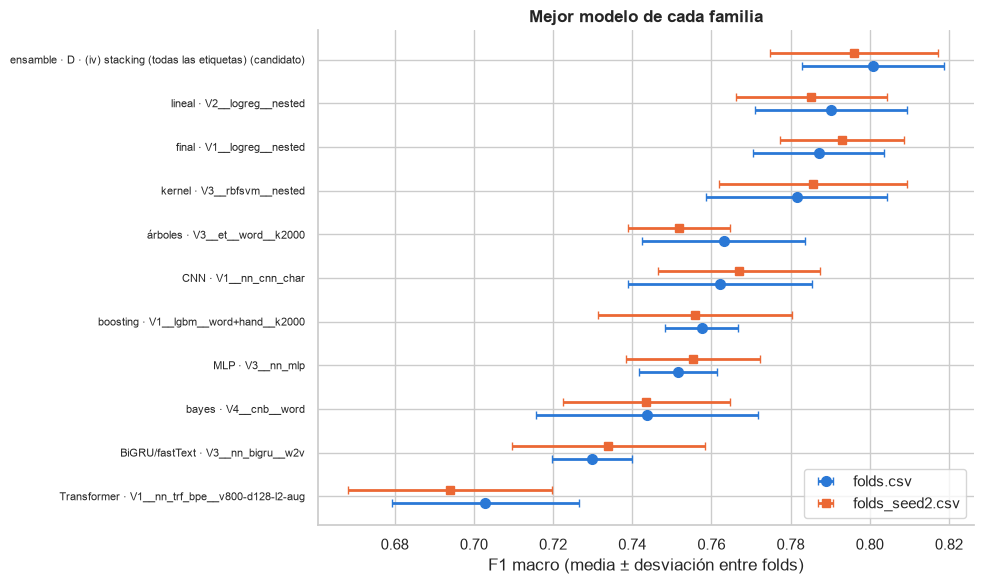

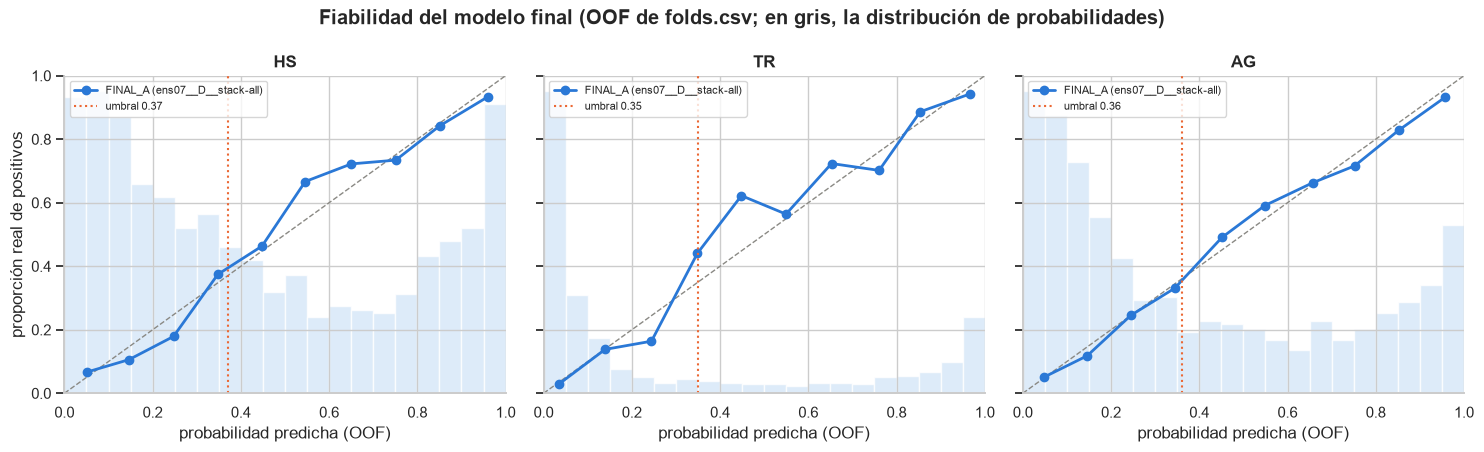

In [36]:
fig, ax = plt.subplots(figsize=(10, 6))
order = MASTER.sort_values("F1 macro")
y = np.arange(len(order))
ax.errorbar(order["F1 macro"], y - 0.15, xerr=order["desv."], fmt="o", color=COLORS[0], ms=7, lw=2, capsize=3,
            label="folds.csv")
ax.errorbar(order["F1 macro folds_seed2"], y + 0.15, xerr=order["desv. folds_seed2"], fmt="s", color=COLORS[1], ms=6,
            lw=2, capsize=3, label="folds_seed2.csv")
ax.set_yticks(y, [f"{f} · {m.replace('__tune-d0.3-lr0.002', '').replace('__tune-d0.5-lr0.002', '')}"
                  for f, m in zip(order["familia"], order["modelo"])], fontsize=8)
ax.set(xlabel="F1 macro (media ± desviación entre folds)", title="Mejor modelo de cada familia")
ax.legend(loc="lower right")
fig.tight_layout()
savefig(fig, "families")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for j, (lab, ax) in enumerate(zip(LABELS, axes)):
    ax.plot([0, 1], [0, 1], ls="--", color="#8a8984", lw=1)
    rel = reliability(Y[:, j], PROBA[:, j])
    ax.plot(rel[:, 0], rel[:, 1], marker="o", color=COLORS[0], lw=2, label=f"FINAL_A ({FA['name']})")
    ax.axvline(FA["model"].thresholds[lab], color=COLORS[1], ls=":", lw=1.5, label=f"umbral {FA['model'].thresholds[lab]:.2f}")
    ax2 = ax.twinx()
    ax2.hist(PROBA[:, j], bins=20, range=(0, 1), color="#d5e6f8", alpha=0.8)
    ax2.set_yticks([])
    ax.set_zorder(ax2.get_zorder() + 1)
    ax.patch.set_visible(False)
    ax.set(title=lab, xlabel="probabilidad predicha (OOF)", ylabel="proporción real de positivos" if j == 0 else "",
           xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=8, loc="upper left")
fig.suptitle("Fiabilidad del modelo final (OOF de folds.csv; en gris, la distribución de probabilidades)", fontweight="bold")
fig.tight_layout()
savefig(fig, "reliability_final")
plt.show()

**Interpretación:**
- **Ranking con el protocolo de este notebook** (`folds.csv` / `folds_seed2`):
  - ensamble 0.8008 / 0.7961;
  - lineal (V2 logística) 0.7902 / 0.7852;
  - kernel (SVM RBF) 0.7815 / 0.7856;
  - árboles 0.7631 / 0.7519;
  - CNN de caracteres 0.7621 / 0.7670;
  - boosting 0.7575;
  - MLP 0.7515;
  - Complement NB 0.7437;
  - BiGRU 0.7298;
  - Transformer 0.7029 / 0.6940.
- **`folds_seed2` confirma el orden,** salvo que la SVM RBF empata con el lineal y ExtraTrees baja (−0.011).
- **El protocolo de meseta queda dentro de ±0.004 de las cifras del registro** (por ejemplo, lineal 0.7902 frente a 0.7937).
- **Coste:**
  - el ensamble suma ≈606 s de CV y 113 MB, sobre todo por el MLP (67 MB) y ExtraTrees (35 MB);
  - el mejor lineal: 48 s y 0.5 MB;
  - la CV del ensamble incluye unos segundos del crossfit, que varían ligeramente entre ejecuciones (606.1 frente a 606.0 s).
- **Kaggle:** la columna solo tiene el puntaje que existía antes de esta ejecución (V2__logreg__nested, 0.77714). Los de FINAL_A y FINAL_B están en `PROGRESO.md` §8.

## 12. Conclusiones

1. **El ensamble mejora de verdad, aunque poco.**
   - Stacking con regresión logística sobre los logits de las 3 etiquetas de los 10 modelos del pool: 0.8008 ± 0.0180, frente a 0.7902 de la mejor logística.
   - Δ +0.0106 (4/5) en `folds.csv` y +0.0108 (5/5) en `folds_seed2`: cumple la regla fijada de antemano. **FINAL_A = `ens07__D__stack-all`.**
2. **La diversidad útil la aportan las redes:**
   - C (lineales + redes) gana con los seis métodos;
   - B (lineales + clásicos) empata;
   - quitar las redes del ensamble cuesta −0.0095;
   - el núcleo lineal solo no gana nada, porque sus errores están correlacionados entre 0.78 y 0.93.
3. **Calibración (P10):**
   - Platt es el mejor método; NB, ExtraTrees y NB-SVM son los descalibrados;
   - para el F1 con umbral ajustado, calibrar casi no importa. Importa para ponderar modelos;
   - la información entre etiquetas (stacking con las 3) aporta +0.001–0.004 de forma consistente.
4. **Umbral de meseta y jerarquía:** sus efectos (±0.004) están dentro del ruido. Se mantienen como estaban decididos.
5. **FINAL_B = `V1__logreg__nested`:** el modelo único más simple empatado con el mejor (0.7871; 0.7930 en `folds_seed2`). Es una alternativa robusta y barata.
6. **Errores:**
   - el 23.9% de los tuits lo fallan igual el ensamble y el mejor único;
   - el 11.3% tiene alguna etiqueta que fallan los 10 modelos. En la revisión manual, 12 de 20 son insultos sin odio y 4 dependen de un contexto ausente;
   - el techo lo marca la definición de la tarea (odio frente a insulto), no la capacidad de los modelos.
7. **Pendientes:**
   - P3: el artefacto de comillas valdría +0.005 en F1 macro, pero sigue desactivado;
   - P13: más texto para preentrenar;
   - P14: segunda ejecución completa del 05.
8. **Kaggle (después de la ejecución, sin usarlo para decidir):**
   - FINAL_A obtuvo 0.78273, el mejor puntaje público hasta ahora;
   - FINAL_B obtuvo 0.76466, por debajo de la logística de V2 (0.77714);
   - con solo una parte del test en el público, diferencias de ≈0.01 están dentro del ruido (H44).